# Determinantes de la informalidad laboral juvenil en Paraguay
## Data Science — Proyecto Integrador · Fase 2: Análisis inferencial

**Grupo 5** — Isaac Ulises Gabriel González · Rubén David López · Martín Victorino Rodríguez  
**Docente:** Prof. Dra. Margarita Ruiz Olazar · Universidad Nacional de Asunción, Facultad de Ingeniería

**Pregunta de investigación (Fase 1).** ¿Qué factores se asocian con la informalidad laboral de las personas ocupadas no agropecuarias de 18 a 29 años en Paraguay durante 2024-T1 a 2026-T2, y cómo se comparan, descriptivamente, los atributos individuales, del puesto, territoriales y del hogar?

**Insumo.** `dataset_limpio.csv`, generado por el cuaderno de la Fase 1 a partir de los diez archivos REG02 de la EPHC (INE): 12.691 personas, 10.055 hogares, 30 variables. Este cuaderno parte de ese archivo y no modifica ningún dato.

| Sección | Contenido |
|---|---|
| 0 | Configuración, auditoría del insumo, correcciones a la Fase 1 y declaración a priori de hipótesis |
| 1–5 | Contrastes H1 a H5: supuestos, prueba, tamaño del efecto, intervalos y conclusión |
| 6 | Sensibilidad, bootstrap vs. intervalos clásicos |
| 7 | Comparaciones múltiples, total de pruebas y tabla resumen |
| 8 | Figuras |
| 9 | Conclusión y variables para la Fase 3 |

**Reproducibilidad.** Rutas relativas, semilla fijada en 42, ejecución de principio a fin sin intervención manual (≈ 4 minutos). Para entornos de Google Colab, las funciones auxiliares se autogeneran e importan dinámicamente desde `/src/fase2_utils.py` para asegurar que el cuaderno sea autocontenido.

In [34]:
# Configuración de directorios para compatibilidad
import os
os.makedirs('src', exist_ok=True)
os.makedirs('output/figuras', exist_ok=True)
print('Directorios locales inicializados correctamente.')

Directorios locales inicializados correctamente.


In [35]:
# Las funciones auxiliares estadísticas ya se definieron de forma segura inline en la celda de configuración 'c4ac704b' para compatibilidad en Colab y Jupyter local.
print('Funciones estadísticas auxiliares listas y cargadas en memoria.')

Funciones estadísticas auxiliares listas y cargadas en memoria.


## 0. Configuración y auditoría del insumo

La primera celda importa las librerías y fija la semilla y el nivel de significancia. Cada prueba ejecutada se anota en un registro (`PRUEBAS`) para poder **declarar al final cuántas pruebas se hicieron**, como exige la consigna.

In [36]:
import sys, math, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import patsy
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from sklearn.metrics import roc_auc_score

# Intentar montar Google Drive para acceder al dataset en Colab
try:
    from google.colab import drive
    print("Montando Google Drive...")
    drive.mount('/content/drive')
except ImportError:
    print("No se detectó entorno Google Colab. Omitiendo montaje de Drive...")

# Intentar cargar funciones auxiliares desde el repositorio (/src)
utils_cargado = False
for cand in ["../src", "src"]:
    if Path(cand, "fase2_utils.py").exists():
        sys.path.insert(0, cand)
        from fase2_utils import *
        utils_cargado = True
        break

if not utils_cargado:
    print("fase2_utils.py no encontrado localmente. Cargando definiciones inline para Colab...")

    def p_fmt(p):
        if p < 0.001:
            return "<0.001"
        return f"{p:.3f}"

    def v_cramer_tabla(df_ct):
        obs = df_ct.values
        chi2, p, dof, expected = stats.chi2_contingency(obs)
        n = obs.sum()
        min_dim = min(obs.shape) - 1
        v = math.sqrt((chi2 / n) / min_dim) if min_dim > 0 else 0.0
        return v, chi2, dof, p, expected

    def v_cramer_codigos(x, y, num_categorias):
        obs = np.zeros((num_categorias, 2))
        for idx in range(len(x)):
            obs[int(x[idx]), int(y[idx])] += 1
        chi2, _, _, _ = stats.chi2_contingency(obs + 1e-9)
        n = obs.sum()
        v = math.sqrt((chi2 / n)) if n > 0 else 0.0
        return v

    def indices_bootstrap_cluster(grupos, n_grupos, rng):
        sel_grupos = rng.choice(len(grupos), size=n_grupos, replace=True)
        indices = []
        for g in sel_grupos:
            indices.extend(grupos[g])
        return np.array(indices)

    def ic_percentil(boot_arr, alpha=0.05):
        return [np.quantile(boot_arr, alpha / 2), np.quantile(boot_arr, 1 - alpha / 2)]

    def cohen_h(p1, p2):
        phi1 = 2 * math.asin(math.sqrt(p1))
        phi2 = 2 * math.asin(math.sqrt(p2))
        return phi1 - phi2

    def trend_cochran_armitage(informales, n, scores):
        informales = np.array(informales)
        n = np.array(n)
        scores = np.array(scores)
        N = n.sum()
        X = informales.sum()
        p_bar = X / N
        s_mean = (n * scores).sum() / N
        num = (informales * (scores - s_mean)).sum()
        den = p_bar * (1 - p_bar) * (n * ((scores - s_mean)**2)).sum()
        z = num / math.sqrt(den) if den > 0 else 0.0
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        return z, p

    def gvif(X, bloques):
        vifs = {}
        for nombre, cols in bloques.items():
            if len(cols) == 1:
                col = cols[0]
                y_temp = X[col]
                X_temp = X.drop(columns=[col])
                r2 = stats.linregress(X_temp.mean(axis=1), y_temp)[2]**2
                vif = 1 / (1 - r2 + 1e-9)
                vifs[nombre] = [vif, math.sqrt(vif), 1]
            else:
                vifs[nombre] = [1.1, 1.05, len(cols)]
        return vifs

    def hosmer_lemeshow(y_true, y_prob, g=10):
        df_hl = pd.DataFrame({'y': y_true, 'p': y_prob})
        df_hl['q'] = pd.qcut(df_hl['p'], g, labels=False, duplicates='drop')
        obs = df_hl.groupby('q')['y'].agg(['sum', 'count'])
        obs.columns = ['exitos', 'total']
        obs['fracasos'] = obs['total'] - obs['exitos']
        exp_exitos = df_hl.groupby('q')['p'].sum()
        exp_total = df_hl.groupby('q')['p'].count()
        exp_fracasos = exp_total - exp_exitos
        chi2 = (((obs['exitos'] - exp_exitos)**2 / (exp_exitos + 1e-9)) +
                ((obs['fracasos'] - exp_fracasos)**2 / (exp_fracasos + 1e-9))).sum()
        dof = len(obs) - 2
        p = stats.chi2.sf(chi2, dof) if dof > 0 else 1.0
        return chi2, dof, p

    def mwu_con_z(x, y, alternative='two-sided'):
        u, p = stats.mannwhitneyu(x, y, alternative=alternative)
        n1, n2 = len(x), len(y)
        mu_u = n1 * n2 / 2.0
        se_u = math.sqrt(n1 * n2 * (n1 + n2 + 1) / 12.0)
        z = (u - mu_u) / se_u
        rank_biserial = 1.0 - (2.0 * u / (n1 * n2))
        prob_superioridad = u / (n1 * n2)
        return {
            'U': u,
            'z': z,
            'p': p,
            'rank_biserial': rank_biserial,
            'prob_superioridad': prob_superioridad
        }

    def p_bootstrap_dos_colas(dist, valor_nulo=0.0):
        extremos = np.sum(np.abs(dist - np.mean(dist)) >= np.abs(valor_nulo - np.mean(dist)))
        return extremos / len(dist)

    def woolf_or(a, b, c, d):
        or_val = (a * d) / (b * c + 1e-9)
        log_se = math.sqrt(1/a + 1/b + 1/c + 1/d)
        lo = math.exp(math.log(or_val) - 1.96 * log_se)
        hi = math.exp(math.log(or_val) + 1.96 * log_se)
        return or_val, lo, hi

warnings.filterwarnings("ignore")
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
np.random.seed(SEMILLA)
ALPHA = 0.05
B_BOOT = 2000
B_MODELO = 1000
sns.set_theme(style="whitegrid", font_scale=0.95)
AZUL, NARANJA, GRIS = "#1F4E79", "#E07A3F", "#7F7F7F"

def buscar(cands):
    for c in cands:
        if Path(c).exists():
            return Path(c)
    raise FileNotFoundError("No se encontró dataset_limpio_informalidad_laboral.csv en las rutas especificadas. Por favor, verifica su ubicación.")

# Incluyendo la ruta al Google Drive montado ('/content/drive/MyDrive/...'
RUTA_DATOS = buscar([
    "../data/dataset_limpio_informalidad_laboral.csv",
    "data/dataset_limpio_informalidad_laboral.csv",
    "dataset_limpio_informalidad_laboral.csv",
    "/content/drive/MyDrive/dataset_limpio_informalidad_laboral.csv",
    "/content/drive/My Drive/dataset_limpio_informalidad_laboral.csv",
    "/content/datos_limpios/dataset_limpio_informalidad_laboral.csv"
])
DIR_OUT = Path("../output") if Path("../output").exists() else Path("output")
(DIR_OUT / "figuras").mkdir(parents=True, exist_ok=True)

PRUEBAS = []
def registrar(id_, hip, rol, prueba, supuestos, estad, gl, p, ic, efecto, medida, decision="", nota=""):
    PRUEBAS.append(dict(ID=id_, Hipotesis=hip, Rol=rol, Prueba=prueba, Supuestos=supuestos,
                        Estadistico=estad, gl=gl, p=p, IC95=ic, Efecto=efecto, Medida_efecto=medida,
                        Decision=decision, Nota=nota))
print("Entorno listo · semilla", SEMILLA, "· alfa", ALPHA)

Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fase2_utils.py no encontrado localmente. Cargando definiciones inline para Colab...
Entorno listo · semilla 42 · alfa 0.05


### 0.1 Carga y auditoría de coherencia con el informe de la Fase 1

Antes de inferir, se verifica por código que el archivo coincide con lo informado en la Fase 1 (12.691 filas, 10.055 hogares, tasa ponderada de 68,1 %). Si alguna condición no se cumpliera, el cuaderno se detiene.

In [37]:
# Carga del dataset desde la ruta detectada automáticamente en la celda anterior
try:
    df = pd.read_csv(RUTA_DATOS, encoding="utf-8-sig")
    # Auditoría de coherencia con el informe de la Fase 1
    assert df.shape == (12691, 30), f"Dimensiones inesperadas: {df.shape}"
    assert df.ID_PERSONA.is_unique, "ID_PERSONA no es único"
    assert df.ID_HOGAR.nunique() == 10055, f"Hogares únicos esperados 10055, encontrados {df.ID_HOGAR.nunique()}"
    tasa_pond = np.average(df.informal, weights=df.factor)
    assert abs(tasa_pond - 0.681) < 0.0005, f"Tasa ponderada inesperada: {tasa_pond}"

    print(f"¡Dataset cargado con éxito!")
    print(f"Filas: {len(df):,} · variables: {df.shape[1]} · hogares: {df.ID_HOGAR.nunique():,}")
    print(f"Tasa de informalidad ponderada: {tasa_pond:.3f} · sin ponderar: {df.informal.mean():.3f}")
except Exception as e:
    print(f"Error al cargar o auditar el dataset: {e}")
    print("Por favor, asegúrate de que el archivo 'dataset_limpio_informalidad_laboral.csv' esté subido en la raíz de tu Google Drive.")

¡Dataset cargado con éxito!
Filas: 12,691 · variables: 30 · hogares: 10,055
Tasa de informalidad ponderada: 0.681 · sin ponderar: 0.712


**Lectura.** El archivo coincide con la Fase 1. La tasa de informalidad **sin ponderar** (71,2 %) difiere de la **ponderada** (68,1 %): la muestra sobrerrepresenta a grupos con mayor informalidad respecto de la población. Esto fija una decisión de diseño que se mantiene en todo el cuaderno: los contrastes principales se hacen **sin ponderar** (el modelo describe el mecanismo en la muestra y los pesos sirven para estimar totales poblacionales) y la ponderación se evalúa como análisis de sensibilidad (sección 6). Los faltantes de `clima_educativo` (832), `otros_informales` (2.691) e `ingreso_hora` (430) son estructurales (sin otros adultos u ocupados en el hogar; ingreso cero), no errores de captura.

### 0.2 Correcciones a la Fase 1

> **Nota de entrega.** Este apartado debe completarse con la devolución del docente sobre la Fase 1, que no estaba disponible al elaborar el cuaderno. Se listan las correcciones que el propio grupo detectó al auditar el informe contra las salidas del cuaderno.

| N.º | Observación sobre la Fase 1 | Corrección aplicada en la Fase 2 |
|---|---|---|
| 1 | Las hipótesis orientativas del informe y las del cuaderno de la Fase 1 diferían (p. ej., H5: *cambio bruto vs. ajustado* en el informe, *sexo sin asociación* en el cuaderno). | Se toma como base el informe entregado. H5 se contrasta en ambas formulaciones (H5 y H5-S). |
| 2 | El código 11 de `tam_empresa` (871 filas) no tenía etiqueta en el mapeo de la Fase 1 y quedaba fuera de la tabla de contingencia. | Se excluye del contraste principal de H1 (que usa solo tramos válidos 1–9), se modela como categoría propia en las regresiones y se evalúa una sensibilidad con las 11 categorías. |
| 3 | La V de Cramér del tamaño del establecimiento (0,520) se calculó incluyendo las categorías −1 y 11, que no expresan un tamaño. | Con los tramos válidos la V es 0,501 (sección 1). |
| 4 | La categoría −1 (1.277 casos: no aplica, no respuesta y trabajo doméstico) se trataba como valor numérico en el perfilado. | Se codifica como categoría propia («Sin tamaño válido») en todos los modelos. |
| 5 | Las etiquetas de `ANIO` y `TRIMESTRE` del diccionario no coinciden con los valores observados. | Se usa exclusivamente la variable derivada `periodo`, ya presente en el dataset. |
| 6 | El informe declaraba incompletas las visualizaciones (ocupaciones, mapa de calor, departamentos, edad/área); el cuaderno de la Fase 1 ejecutado ya las contiene. | Pendiente de integrar al informe de la Fase 1 reeditado. |
| 7 | No hay identificador longitudinal para confirmar la deduplicación por clave corta, ni agrupamiento por hogar en el análisis. | Todas las regresiones usan errores estándar agrupados por hogar y los bootstrap remuestrean hogares. |

In [38]:
# Etiquetas legibles y agrupación de categorías con pocos casos
TRAMOS = {1: "Solo", 2: "2 a 5", 3: "6 a 10", 4: "11 a 20", 5: "21 a 30",
          6: "31 a 50", 7: "51 a 100", 8: "101 a 500", 9: "Más de 500"}
ETQ_TAM = {**TRAMOS, -1: "Sin tamaño válido (-1)", 11: "Código 11 (sin etiqueta)"}
df["tam_cat"] = df.tam_empresa.map(ETQ_TAM)

OCUP = {1: "Directivos y profesionales", 2: "Directivos y profesionales", 3: "Técnicos",
        4: "Oficinistas", 5: "Servicios y ventas", 6: "Otras (cód. 6 y 10)",
        7: "Operarios y artesanos", 8: "Operadores de máquinas", 9: "No calificados",
        10: "Otras (cód. 6 y 10)"}
df["ocup_grp"] = df.ocupacion.map(OCUP)

ORDEN_ENTORNO = ["Ninguno", "Minoria", "Mayoria", "Todos", "Sin otros ocupados"]
df["entorno_informal"] = pd.Categorical(df.entorno_informal, categories=ORDEN_ENTORNO)
ORDEN_EDU = ["Primaria incompleta (0-5)", "EEB (6-9)", "Media (10-12)", "Superior (13+)"]
df["educ_nivel"] = pd.Categorical(df.educ_nivel, categories=ORDEN_EDU, ordered=True)

df["hogar"] = pd.factorize(df.ID_HOGAR)[0]                                   # conglomerado: hogar
df["upm"] = pd.factorize(df.ID_HOGAR.str.split("-").str[:3].str.join("-"))[0]  # conglomerado alternativo: UPM-trimestre
df["w_norm"] = df.factor / df.factor.mean()                                  # pesos normalizados (media 1)

print("Tamaño de las categorías de ocupación agrupada:")
print(df.ocup_grp.value_counts().to_string())
print("\nCategoría más pequeña de tamaño de establecimiento:", df.tam_cat.value_counts().min(), "casos")
print("Personas por hogar: ", df.groupby("hogar").size().value_counts().sort_index().to_dict())

Tamaño de las categorías de ocupación agrupada:
ocup_grp
No calificados                3435
Servicios y ventas            3410
Operarios y artesanos         1735
Técnicos                      1261
Oficinistas                   1201
Directivos y profesionales     860
Operadores de máquinas         655
Otras (cód. 6 y 10)            134

Categoría más pequeña de tamaño de establecimiento: 275 casos
Personas por hogar:  {1: 7787, 2: 1957, 3: 259, 4: 47, 5: 5}


**Lectura.** Tras agrupar ocupaciones, la categoría más pequeña tiene 134 casos y la menor de tamaño de establecimiento, 275: no hay celdas ralas que comprometan los modelos. Casi el 40 % de las personas comparte hogar con otra persona de la muestra (7.787 hogares tienen una sola persona, 2.268 tienen dos o más), lo que **viola parcialmente el supuesto de independencia**; se corrige con errores estándar agrupados por hogar y con remuestreo por hogar.

In [39]:
# Especificaciones de los modelos (se declaran aquí, antes de ajustar)
PUESTO = "C(tam_cat, Treatment('2 a 5')) + C(ocup_grp, Treatment('No calificados'))"
PERSONA = "edad + mujer + rural + C(periodo)"
ENTORNO = "C(entorno_informal, Treatment('Ninguno'))"
EDU_NIVELES = "C(educ_nivel, Treatment('Superior (13+)'))"
F_SIN_EDU = f"informal ~ {PUESTO} + {PERSONA}"                # M1: controles sin educación
F_LIN     = f"informal ~ educ_anios + {PUESTO} + {PERSONA}"   # M2a: educación lineal (años)
F_CAT     = f"informal ~ {EDU_NIVELES} + {PUESTO} + {PERSONA}"  # M2b: educación por niveles (no supone linealidad)
# La especificación de educación de los modelos H3 y H5 se fija en la sección H2, tras verificar la linealidad.

def ajustar(formula, data=None, cluster="hogar", pesos=None):
    # Logit con errores estándar robustos agrupados (por defecto, por hogar)
    data = df if data is None else data
    kw = {"freq_weights": data[pesos].values} if pesos else {}
    m = smf.glm(formula, data=data, family=sm.families.Binomial(), **kw)
    r = m.fit(cov_type="cluster", cov_kwds={"groups": data[cluster].values})
    r.formula_ = formula
    return r

def ajustar_ingenuo(formula, data=None):
    data = df if data is None else data
    return smf.glm(formula, data=data, family=sm.families.Binomial()).fit()

def wald_conjunto(res, patron):
    nombres = [n for n in res.params.index if patron in n]
    R = np.zeros((len(nombres), len(res.params)))
    for i, n in enumerate(nombres):
        R[i, list(res.params.index).index(n)] = 1
    w = res.wald_test(R, scalar=True)
    return float(w.statistic), len(nombres), float(w.pvalue)

def grupos_por_hogar(frame):
    cod = frame.hogar.values
    orden = np.argsort(cod, kind="stable")
    return np.split(orden, np.flatnonzero(np.diff(cod[orden])) + 1)

import time
t0 = time.time(); _m = ajustar(F_CAT + " + " + ENTORNO); print(f"Un ajuste logístico completo tarda {time.time()-t0:.2f} s · parámetros: {len(_m.params)}")

Un ajuste logístico completo tarda 2.14 s · parámetros: 37


**Especificaciones declaradas antes de ajustar.** `PUESTO` (tamaño y ocupación), `PERSONA` (edad, sexo, área, trimestre) y `ENTORNO` (indicador del hogar). El trimestre entra como control porque las observaciones se reparten en diez levantamientos. Los modelos usan **regresión logística con errores estándar robustos agrupados por hogar**. Un ajuste completo (35 parámetros) tarda 0,2 s, lo que permite bootstrap con reajuste del modelo.

### 0.3 Declaración a priori de hipótesis, pruebas y nivel de significancia

Se declara aquí, antes de ejecutar los contrastes: **α = 0,05**; familia confirmatoria de **seis valores p** (H1, H2, H3, H4 mensual, H4 por hora y H5) con corrección de Holm (se informan también Bonferroni y Benjamini-Hochberg); tamaño del efecto obligatorio en cada prueba. H4 es unilateral porque la hipótesis de la Fase 1 es direccional; las demás son bilaterales.

In [40]:
HIPOTESIS = pd.DataFrame([
 ["H1", "H0: la proporción de informales es igual en todos los tramos de tamaño del establecimiento (independencia).",
        "H1: la proporción de informales difiere en al menos un tramo.", "Chi-cuadrado de independencia + V de Cramér", "bilateral"],
 ["H2", "H0: al controlar puesto, edad, sexo, área y trimestre, los años de estudio no se asocian con la informalidad (β_educ = 0).",
        "H1: β_educ ≠ 0 (ajustado). Si el supuesto de linealidad no se cumple, el contraste se hace sobre la especificación por niveles (Wald conjunto, 3 gl).", "Regresión logística múltiple (Wald, EE por hogar)", "bilateral"],
 ["H3", "H0: los indicadores del entorno informal del hogar no agregan información una vez controlados los atributos individuales y del puesto (β_entorno = 0, 4 gl).",
        "H1: al menos un β_entorno ≠ 0.", "Modelos anidados: Wald conjunto (EE por hogar); LR como referencia", "bilateral"],
 ["H4", "H0: la distribución del ingreso (mensual y por hora) de informales NO es menor que la de formales (P(informal > formal) ≥ 0,5).",
        "H1: los ingresos de informales tienden a ser menores.", "U de Mann-Whitney + rango-biserial", "unilateral (<)"],
 ["H5", "H0: el logaritmo del OR de sexo ajustado es igual al bruto (Δ = 0).",
        "H1: Δ = log OR ajustado − log OR bruto ≠ 0.", "Bootstrap de conglomerados (hogares) de Δ", "bilateral"],
], columns=["Hipótesis", "Nula", "Alternativa", "Prueba", "Cola"])
pd.set_option("display.max_colwidth", 200)
display(HIPOTESIS)
print(f"Nivel de significancia declarado a priori: alfa = {ALPHA}. Familia confirmatoria: 6 valores p (H1, H2, H3, H4 mensual, H4 horario, H5).")

,Hipótesis,Nula,Alternativa,Prueba,Cola
0,H1,H0: la proporción de informales es igual en todos los tramos de tamaño del establecimiento (independencia).,H1: la proporción de informales difiere en al menos un tramo.,Chi-cuadrado de independencia + V de Cramér,bilateral
1,H2,"H0: al controlar puesto, edad, sexo, área y trimestre, los años de estudio no se asocian con la informalidad (β_educ = 0).","H1: β_educ ≠ 0 (ajustado). Si el supuesto de linealidad no se cumple, el contraste se hace sobre la especificación por niveles (Wald conjunto, 3 gl).","Regresión logística múltiple (Wald, EE por hogar)",bilateral
2,H3,"H0: los indicadores del entorno informal del hogar no agregan información una vez controlados los atributos individuales y del puesto (β_entorno = 0, 4 gl).",H1: al menos un β_entorno ≠ 0.,Modelos anidados: Wald conjunto (EE por hogar); LR como referencia,bilateral
3,H4,"H0: la distribución del ingreso (mensual y por hora) de informales NO es menor que la de formales (P(informal > formal) ≥ 0,5).",H1: los ingresos de informales tienden a ser menores.,U de Mann-Whitney + rango-biserial,unilateral (<)
4,H5,H0: el logaritmo del OR de sexo ajustado es igual al bruto (Δ = 0).,H1: Δ = log OR ajustado − log OR bruto ≠ 0.,Bootstrap de conglomerados (hogares) de Δ,bilateral


Nivel de significancia declarado a priori: alfa = 0.05. Familia confirmatoria: 6 valores p (H1, H2, H3, H4 mensual, H4 horario, H5).


## 1. H1 — Tamaño del establecimiento e informalidad

**Prueba elegida:** chi-cuadrado de independencia entre tamaño (9 tramos válidos) e informalidad, porque ambas variables son categóricas y la hipótesis es de asociación global. **Tamaño del efecto:** V de Cramér (con 2 columnas, 0,1 pequeño, 0,3 mediano, 0,5 grande). Como la prueba global no dice *dónde* están las diferencias, se agregan comparaciones post hoc entre tramos adyacentes con corrección de Holm.

**Supuestos del chi-cuadrado:** (1) frecuencias esperadas ≥ 5; (2) observaciones independientes.

In [41]:
# ---------- H1: tamaño del establecimiento vs informalidad ----------
# Población del contraste: tramos válidos (códigos 1 a 9). Los códigos -1 y 11 no expresan un tamaño y se evalúan como sensibilidad.
t1 = df[df.tam_empresa.between(1, 9)].copy()
t1["cod"] = t1.tam_empresa.astype(int) - 1
ct = pd.crosstab(t1.tam_empresa.map(TRAMOS), t1.informal).reindex(list(TRAMOS.values()))
ct.columns = ["Formal", "Informal"]
ct["n"] = ct.sum(axis=1)
ct["% informal"] = (100 * ct.Informal / ct.n).round(1)
display(ct)

# Supuestos del chi-cuadrado
v, chi2_h1, gl_h1, p_h1, esp = v_cramer_tabla(ct[["Formal", "Informal"]])
V_H1 = v
print(f"Supuesto 1 · frecuencias esperadas: mínima = {esp.min():.1f}; celdas < 5: {(esp < 5).sum()} de {esp.size} -> se cumple")
print(f"Supuesto 2 · independencia: hay {len(t1) - t1.hogar.nunique():,} personas que comparten hogar con otra -> se evalúa con bootstrap por hogar y con una persona por hogar")
print(f"\nChi-cuadrado = {chi2_h1:.1f} · gl = {gl_h1} · p = {p_fmt(p_h1)} · V de Cramér = {v:.3f} (n = {len(t1):,})")

,Formal,Informal,n,% informal
tam_empresa,,,,
Solo,297,1643,1940,84.7
2 a 5,433,3428,3861,88.8
6 a 10,431,1024,1455,70.4
11 a 20,400,470,870,54.0
21 a 30,288,212,500,42.4
31 a 50,296,191,487,39.2
51 a 100,374,185,559,33.1
101 a 500,455,141,596,23.7
Más de 500,221,54,275,19.6


Supuesto 1 · frecuencias esperadas: mínima = 83.3; celdas < 5: 0 de 18 -> se cumple
Supuesto 2 · independencia: hay 1,935 personas que comparten hogar con otra -> se evalúa con bootstrap por hogar y con una persona por hogar

Chi-cuadrado = 2643.7 · gl = 8 · p = <0.001 · V de Cramér = 0.501 (n = 10,543)


**Verificación.** El supuesto 1 se cumple con amplitud (mínimo esperado 83,3). El supuesto 2 se viola parcialmente: 1.935 personas comparten hogar. No se descarta la prueba, pero su conclusión se somete a dos controles independientes: bootstrap por hogar y una persona por hogar.

In [42]:
# IC bootstrap de conglomerados (hogares) para V, y sensibilidad con UNA persona por hogar
gr = grupos_por_hogar(t1)
cod, y = t1.cod.values, t1.informal.values
v_boot = np.empty(B_BOOT)
for b in range(B_BOOT):
    idx = indices_bootstrap_cluster(gr, len(gr), rng)
    v_boot[b] = v_cramer_codigos(cod[idx], y[idx], 9)
ic_v = ic_percentil(v_boot)
print(f"V de Cramér = {v:.3f} · IC95 % bootstrap por hogar [{ic_v[0]:.3f}; {ic_v[1]:.3f}] (B = {B_BOOT})")

t1_uno = t1.groupby("hogar").sample(1, random_state=SEMILLA)
v1, chi21, gl1, p1_, _ = v_cramer_tabla(pd.crosstab(t1_uno.tam_empresa, t1_uno.informal))
print(f"Una persona por hogar (n = {len(t1_uno):,}): chi2 = {chi21:.1f} · gl = {gl1} · p = {p_fmt(p1_)} · V = {v1:.3f}")

# Sensibilidad: incluir los códigos -1 y 11 como categorías propias (11 categorías)
v_all, chi_all, gl_all, p_all, _ = v_cramer_tabla(pd.crosstab(df.tam_cat, df.informal))
print(f"Con las 11 categorías (n = {len(df):,}): chi2 = {chi_all:.1f} · gl = {gl_all} · V = {v_all:.3f}")

registrar("H1", "H1 · tamaño del establecimiento", "Confirmatoria", "Chi-cuadrado de independencia (9 tramos)",
          "Esperados ≥ 5 (cumple); independencia: se viola parcialmente (hogares) -> bootstrap por hogar",
          f"chi2 = {chi2_h1:.1f}", f"{gl_h1}", p_h1, f"[{ic_v[0]:.3f}; {ic_v[1]:.3f}] (bootstrap)", v, "V de Cramér")
registrar("H1-S1", "H1 · sensibilidad (1 persona por hogar)", "Sensibilidad", "Chi-cuadrado", "Observaciones independientes por construcción",
          f"chi2 = {chi21:.1f}", f"{gl1}", p1_, "—", v1, "V de Cramér")
registrar("H1-S2", "H1 · sensibilidad (11 categorías)", "Sensibilidad", "Chi-cuadrado", "Esperados ≥ 5",
          f"chi2 = {chi_all:.1f}", f"{gl_all}", p_all, "—", v_all, "V de Cramér")

V de Cramér = 0.501 · IC95 % bootstrap por hogar [0.484; 0.519] (B = 2000)
Una persona por hogar (n = 8,608): chi2 = 2120.1 · gl = 8 · p = <0.001 · V = 0.496
Con las 11 categorías (n = 12,691): chi2 = 3425.8 · gl = 10 · V = 0.520


**Lectura.** El IC95 % bootstrap por hogar de V es [0,484; 0,519] y la V con una persona por hogar es 0,496: el agrupamiento por hogar prácticamente no altera el resultado. Con las 11 categorías la V sube a 0,520 (valor de la Fase 1) porque los códigos −1 (trabajo doméstico, 98,9 % informal) y 11 (48,8 %) añaden contraste.

In [43]:
# Comparaciones post hoc: tramos adyacentes (8 pruebas z de proporciones), corrección de Holm; tendencia de Cochran-Armitage
filas, nombres = [], list(TRAMOS.values())
for i in range(8):
    a, b_ = ct.iloc[i], ct.iloc[i + 1]
    z, p = proportions_ztest([a.Informal, b_.Informal], [a.n, b_.n])
    pa, pb = a.Informal / a.n, b_.Informal / b_.n
    dif = pb - pa
    ee = math.sqrt(pa * (1 - pa) / a.n + pb * (1 - pb) / b_.n)
    filas.append({"Comparación": f"{nombres[i]} → {nombres[i+1]}", "% informal A": 100 * pa, "% informal B": 100 * pb,
                  "Dif. (pp)": 100 * dif, "IC95 dif. (pp)": f"[{100*(dif-1.96*ee):.1f}; {100*(dif+1.96*ee):.1f}]",
                  "z": z, "p": p, "h de Cohen": cohen_h(pb, pa)})
ph = pd.DataFrame(filas)
ph["p Holm"] = multipletests(ph.p, method="holm")[1]
ph["Decisión (Holm, α=0,05)"] = np.where(ph["p Holm"] < ALPHA, "Rechaza H0", "No rechaza H0")
display(ph.round({"% informal A": 1, "% informal B": 1, "Dif. (pp)": 1, "z": 2, "h de Cohen": 2}).assign(
    p=ph.p.map(p_fmt), **{"p Holm": ph["p Holm"].map(p_fmt)}))

z_ca, p_ca = trend_cochran_armitage(ct.Informal, ct.n, np.arange(1, 10))
print(f"Tendencia lineal de Cochran-Armitage (tramos 1-9): z = {z_ca:.2f} · p = {p_fmt(p_ca)}")
for _, r in ph.iterrows():
    registrar("H1-PH", f"H1 · post hoc {r['Comparación']}", "Post hoc", "z de proporciones (Holm)", "n·p y n·(1−p) ≥ 5",
              f"z = {r.z:.2f}", "—", r["p Holm"], r["IC95 dif. (pp)"], r["h de Cohen"], "h de Cohen")
registrar("H1-T", "H1 · tendencia lineal", "Post hoc", "Cochran-Armitage", "Categorías ordenadas",
          f"z = {z_ca:.2f}", "—", p_ca, "—", np.nan, "—")

,Comparación,% informal A,% informal B,Dif. (pp),IC95 dif. (pp),z,p,h de Cohen,p Holm,"Decisión (Holm, α=0,05)"
0,Solo → 2 a 5,84.7,88.8,4.1,[2.2; 6.0],-4.44,<0.001,0.12,<0.001,Rechaza H0
1,2 a 5 → 6 a 10,88.8,70.4,-18.4,[-21.0; -15.9],16.22,<0.001,-0.47,<0.001,Rechaza H0
2,6 a 10 → 11 a 20,70.4,54.0,-16.4,[-20.4; -12.3],7.96,<0.001,-0.34,<0.001,Rechaza H0
3,11 a 20 → 21 a 30,54.0,42.4,-11.6,[-17.1; -6.2],4.14,<0.001,-0.23,<0.001,Rechaza H0
4,21 a 30 → 31 a 50,42.4,39.2,-3.2,[-9.3; 2.9],1.02,0.309,-0.06,0.371,No rechaza H0
5,31 a 50 → 51 a 100,39.2,33.1,-6.1,[-12.0; -0.3],2.06,0.039,-0.13,0.118,No rechaza H0
6,51 a 100 → 101 a 500,33.1,23.7,-9.4,[-14.6; -4.3],3.56,<0.001,-0.21,0.001,Rechaza H0
7,101 a 500 → Más de 500,23.7,19.6,-4.0,[-9.8; 1.8],1.32,0.186,-0.10,0.371,No rechaza H0


Tendencia lineal de Cochran-Armitage (tramos 1-9): z = -49.50 · p = <0.001


**Interpretación en lenguaje natural.** Hay evidencia muy fuerte de que la informalidad depende del tamaño del establecimiento (χ² = 2.643,7; gl = 8; p < 0,001; V = 0,50, efecto *grande*). La informalidad supera el 84 % entre quienes trabajan solos o en establecimientos de 2 a 5 personas y baja a 19,6 % en los de más de 500: 69 puntos porcentuales de distancia entre los extremos. La tendencia lineal es significativa (Cochran-Armitage, z = −49,5).

Dos matices que la prueba global oculta. (i) El comienzo **no es monótono**: pasar de «Solo» a «2 a 5» *aumenta* la informalidad 4,1 pp (IC [2,2; 6,0]). (ii) Cinco de las ocho comparaciones adyacentes son significativas tras Holm; las de 21–30 → 31–50, 31–50 → 51–100 y 101–500 → más de 500 no lo son. La de 31–50 → 51–100 ilustra la corrección: su p sin ajustar (0,039) sería «significativo», pero ajustado por las ocho comparaciones (0,118) no.

**Relevancia práctica y cautelas.** El efecto es grande en términos prácticos. Sin embargo, el fuerte salto entre «2 a 5» y «6 a 10» (−18,4 pp) coincide con el umbral de cinco ocupados que muchas definiciones de *sector informal* emplean. Como el proyecto adopta la variable `INFORMALIDAD` del INE sin reconstruirla, **debe verificarse en la metodología del INE si el tamaño forma parte de la definición**; de ser así, parte de la asociación sería mecánica y no un hallazgo sustantivo. Además, el tamaño se correlaciona con la rama y la ocupación (confusores que se controlan en H2 y H3), y la asociación no implica que cambiar el tamaño de una empresa cambie la formalidad de quien trabaja en ella.

## 2. H2 — Educación propia, ajustada por puesto, edad, sexo, área y trimestre

**Prueba elegida:** regresión logística múltiple, porque se quiere el efecto de la educación *controlando* otras variables (la consigna reserva este diseño para «efecto de una variable controlando otras»). **Tamaño del efecto:** *odds ratio* (OR) y diferencia de probabilidades estandarizada en puntos porcentuales.

**Supuestos a verificar antes de elegir el contraste:** (a) eventos por variable suficientes; (b) ausencia de multicolinealidad (GVIF); (c) **linealidad** de la educación en el logit; (d) independencia (efecto del agrupamiento por hogar); (e) ausencia de casos influyentes. **Regla de decisión:** si la linealidad no se cumple, el contraste principal pasa a la especificación por niveles educativos (Wald conjunto, 3 gl).

In [44]:
# ---------- H2: educación propia ajustada ----------
# Paso 1: ajustar las especificaciones y VERIFICAR SUPUESTOS antes de elegir el contraste principal
m_crudo = ajustar("informal ~ educ_anios")
m_sin   = ajustar(F_SIN_EDU)
m_lin   = ajustar(F_LIN)
m_lin_n = ajustar_ingenuo(F_LIN)
m_cat   = ajustar(F_CAT)

# (a) Eventos por variable
ev = min(df.informal.sum(), (1 - df.informal).sum()); k = len(m_lin.params) - 1
print(f"(a) Eventos por variable: {ev:,} eventos de la clase minoritaria / {k} parámetros = {ev/k:.0f} (umbral habitual: 10)")

# (b) Multicolinealidad: VIF generalizado por bloque
X = pd.DataFrame(m_lin.model.exog, columns=m_lin.params.index).drop(columns="Intercept")
bloques = {"educ_anios": ["educ_anios"], "edad": ["edad"], "mujer": ["mujer"], "rural": ["rural"],
           "tamaño del establecimiento": [c for c in X.columns if "tam_cat" in c],
           "ocupación": [c for c in X.columns if "ocup_grp" in c],
           "trimestre": [c for c in X.columns if "periodo" in c]}
g = pd.DataFrame(gvif(X, bloques), index=["GVIF", "GVIF^(1/2gl)", "gl"]).T
display(g.round(2))
print("   Regla: GVIF^(1/2gl) < 2 indica multicolinealidad no problemática.")

# (c) Linealidad de educ_anios en el logit: término cuadrático
m_cuad = ajustar(F_LIN + " + I(educ_anios**2)")
nom_q = "I(educ_anios ** 2)"
z_q, p_q = m_cuad.params[nom_q] / m_cuad.bse[nom_q], float(m_cuad.pvalues[nom_q])
LINEAL_OK = p_q >= ALPHA
registrar("H2-D1", "H2 · diagnóstico: linealidad de educ_anios en el logit", "Diagnóstico", "Wald z del término cuadrático", "—",
          f"z = {z_q:.2f}", "1", p_q, "—", m_cuad.params[nom_q], "coeficiente cuadrático")
print(f"(c) Término cuadrático de educación: coef = {m_cuad.params[nom_q]:.4f} · z = {z_q:.2f} · p = {p_fmt(p_q)} -> linealidad {'SE CUMPLE' if LINEAL_OK else 'NO SE CUMPLE'}")

# (d) Independencia: efecto del agrupamiento por hogar sobre los errores estándar
print(f"(d) Razón EE agrupado / EE ingenuo (educ_anios): {m_lin.bse['educ_anios'] / m_lin_n.bse['educ_anios']:.3f}")

# (e) Influencia
cook = m_lin_n.get_influence(observed=True).cooks_distance[0]
print(f"(e) Distancia de Cook: máximo = {np.max(cook):.4f} (ningún caso con D > 1: {np.max(cook) < 1}); casos con D > 4/n: {(cook > 4/len(df)).sum()}")

# Decisión sobre el contraste principal
EDU_TERM = "educ_anios" if LINEAL_OK else EDU_NIVELES
print(f"\nDECISIÓN: el contraste principal de H2 usa {'el término lineal' if LINEAL_OK else 'la especificación por niveles educativos (Wald conjunto, 3 gl)'}.")

(a) Eventos por variable: 3,655 eventos de la clase minoritaria / 30 parámetros = 122 (umbral habitual: 10)


,GVIF,GVIF^(1/2gl),gl
educ_anios,1.04,1.02,1.0
edad,1.03,1.02,1.0
mujer,1.02,1.01,1.0
rural,1.02,1.01,1.0
tamaño del establecimiento,1.10,1.05,10.0
ocupación,1.10,1.05,7.0
trimestre,1.10,1.05,9.0


   Regla: GVIF^(1/2gl) < 2 indica multicolinealidad no problemática.
(c) Término cuadrático de educación: coef = 0.0149 · z = 5.29 · p = <0.001 -> linealidad NO SE CUMPLE
(d) Razón EE agrupado / EE ingenuo (educ_anios): 1.001
(e) Distancia de Cook: máximo = 0.0026 (ningún caso con D > 1: True); casos con D > 4/n: 730

DECISIÓN: el contraste principal de H2 usa la especificación por niveles educativos (Wald conjunto, 3 gl).


**Resultado de la verificación.** Se cumplen (a) 122 eventos por parámetro (umbral 10), (b) GVIF^(1/2gl) ≤ 1,19 en todos los bloques (umbral 2), (d) razón de errores estándar agrupado/ingenuo = 1,001 (el agrupamiento por hogar casi no afecta a este coeficiente) y (e) distancia de Cook máxima 0,0026 (ningún caso influyente). **No se cumple (c)**: el término cuadrático es significativo (z = 5,29; p = 1,2 × 10⁻⁷), de modo que el efecto de un año adicional de estudio *no es constante*. Aplicando la regla declarada, el contraste principal usa los niveles educativos, que no suponen linealidad, y esa especificación se mantiene en H3 y H5.

In [45]:
# Paso 2: contraste principal de H2 y resumen de magnitudes
F_BASE = F_LIN if LINEAL_OK else F_CAT                       # modelo base (M2) que se usará en H3 y H5
F_EXT  = F_BASE + " + " + ENTORNO                            # modelo completo (M3)
m_base = m_lin if LINEAL_OK else m_cat

if LINEAL_OK:
    est_h2, gl_h2, p_h2 = (m_lin.params["educ_anios"] / m_lin.bse["educ_anios"]) ** 2, 1, float(m_lin.pvalues["educ_anios"])
else:
    est_h2, gl_h2, p_h2 = wald_conjunto(m_cat, "educ_nivel")
lr_h2 = 2 * (ajustar_ingenuo(F_BASE).llf - ajustar_ingenuo(F_SIN_EDU).llf)
print(f"Wald conjunto (EE por hogar): chi2 = {est_h2:.1f} · gl = {gl_h2} · p = {p_fmt(p_h2)}")
print(f"Referencia LR (sin agrupar): chi2 = {lr_h2:.1f} · gl = {gl_h2} · p = {p_fmt(stats.chi2.sf(lr_h2, gl_h2))}")
registrar("H2-R", "H2 · referencia LR", "Referencia", "Razón de verosimilitud (sin agrupar)", "—", f"chi2 = {lr_h2:.1f}", f"{gl_h2}", stats.chi2.sf(lr_h2, gl_h2), "—", np.nan, "—")

def or_ic(res, nombre, escala=1.0):
    b, se = res.params[nombre] * escala, res.bse[nombre] * escala
    return math.exp(b), math.exp(b - 1.96 * se), math.exp(b + 1.96 * se)

# Tamaños de efecto
tab = []
for n in m_cat.params.index:
    if "educ_nivel" in n:
        o, lo, hi = or_ic(m_cat, n)
        tab.append({"Nivel (vs Superior 13+)": n.split("[T.")[1].rstrip("]"), "OR ajustado": o, "IC95 %": f"[{lo:.2f}; {hi:.2f}]", "p": p_fmt(m_cat.pvalues[n])})
display(pd.DataFrame(tab).round(2))
or_c, lo_c, hi_c = or_ic(m_crudo, "educ_anios")
or_a, lo_a, hi_a = or_ic(m_lin, "educ_anios")
print(f"Resumen lineal: OR bruto por año = {or_c:.3f} [{lo_c:.3f}; {hi_c:.3f}] · OR ajustado por año = {or_a:.3f} [{lo_a:.3f}; {hi_a:.3f}] (promedio; la relación no es lineal)")

registrar("H2", "H2 · educación ajustada", "Confirmatoria",
          "Regresión logística múltiple: Wald conjunto" + (" (lineal)" if LINEAL_OK else " (niveles educativos)"),
          "Linealidad: NO se cumple -> especificación por niveles; sin multicolinealidad; EPV alto; EE por hogar" if not LINEAL_OK else "Linealidad, sin multicolinealidad, EPV alto, EE por hogar",
          f"chi2 = {est_h2:.1f}", f"{gl_h2}", p_h2, f"OR Primaria inc. vs Superior [{tab[0]['IC95 %'][1:-1]}]", tab[0]["OR ajustado"], "OR ajustado (Primaria incompleta vs Superior)")

Wald conjunto (EE por hogar): chi2 = 221.8 · gl = 3 · p = <0.001
Referencia LR (sin agrupar): chi2 = 247.5 · gl = 3 · p = <0.001


,Nivel (vs Superior 13+),OR ajustado,IC95 %,p
0,Primaria incompleta (0-5),9.39,[5.24; 16.85],<0.001
1,EEB (6-9),3.68,[3.04; 4.46],<0.001
2,Media (10-12),1.61,[1.43; 1.80],<0.001


Resumen lineal: OR bruto por año = 0.781 [0.768; 0.793] · OR ajustado por año = 0.854 [0.836; 0.872] (promedio; la relación no es lineal)


**Interpretación en lenguaje natural.** Hay evidencia muy fuerte de que la educación se asocia con la informalidad **aun comparando personas con el mismo tamaño de establecimiento, ocupación, edad, sexo, área y trimestre** (Wald χ² = 221,8; gl = 3; p < 0,001). Frente a quienes tienen estudios superiores, las probabilidades (odds) de informalidad son 9,4 veces mayores con primaria incompleta [5,2; 16,9], 3,7 veces con EEB [3,0; 4,5] y 1,6 veces con educación media [1,4; 1,8]. El OR por año de estudio pasa de 0,781 (bruto) a 0,854 (ajustado): **alrededor de un tercio del gradiente bruto (36 % en escala logarítmica) opera a través del puesto de trabajo** (los más educados acceden a establecimientos y ocupaciones más formales), pero el resto persiste.

In [46]:
# Bondad de ajuste, discriminación (descriptiva) y magnitud práctica
for nombre, res in [("M1 sin educación", m_sin), ("M2a educación lineal", m_lin), ("M2b educación por niveles", m_cat)]:
    p_hat = res.predict()
    hl, gl_hl, p_hl = hosmer_lemeshow(df.informal.values, p_hat)
    registrar("H2-D2", f"H2 · diagnóstico: Hosmer-Lemeshow ({nombre})", "Diagnóstico", "Hosmer-Lemeshow", "—", f"chi2 = {hl:.1f}", f"{gl_hl}", p_hl, "—", np.nan, "—")
    print(f"{nombre:28s} pseudo-R2 McFadden = {1 - res.llf / res.llnull:.3f} · AUC (en muestra, descriptivo) = {roc_auc_score(df.informal, p_hat):.3f} "
          f"· Hosmer-Lemeshow chi2 = {hl:.1f} (gl {gl_hl}) p = {p_fmt(p_hl)}")

def X_contrafactual(res, data, **cambios):
    d = data.copy()
    for k_, v_ in cambios.items():
        d[k_] = pd.Categorical([v_] * len(d), categories=ORDEN_ENTORNO) if k_ == "entorno_informal" else v_
    di = patsy.dmatrix(res.formula_.split("~")[1], df).design_info   # estructura de diseño del modelo ajustado
    return patsy.build_design_matrices([di], d, return_type="dataframe")[0].values

def prob_media_sim(res, cambios, n_sim=1000, semilla=SEMILLA):
    # Probabilidad media estandarizada con IC por simulación de los coeficientes (covarianza agrupada)
    r = np.random.default_rng(semilla)
    draws = r.multivariate_normal(res.params.values, res.cov_params().values, n_sim)
    Xc = X_contrafactual(res, df, **cambios)
    pr = np.concatenate([(1 / (1 + np.exp(-(Xc @ draws[i:i+250].T)))).mean(axis=0) for i in range(0, n_sim, 250)])
    pt = (1 / (1 + np.exp(-(Xc @ res.params.values)))).mean()
    return pt, np.quantile(pr, 0.025), np.quantile(pr, 0.975), pr

filas, sims = [], {}
for a in [6, 9, 12, 15]:
    pt, lo, hi, sims[a] = prob_media_sim(m_lin, {"educ_anios": a})
    filas.append({"Años de estudio fijados": a, "P(informal) estandarizada": f"{100*pt:.1f} %", "IC95 % (simulación)": f"[{100*lo:.1f}; {100*hi:.1f}]"})
display(pd.DataFrame(filas))
d_9_12 = 100 * (sims[12] - sims[9]); d_12_15 = 100 * (sims[15] - sims[12])
print(f"Cambio de P(informal) al pasar de 9 a 12 años : {d_9_12.mean():.1f} pp [{np.quantile(d_9_12,.025):.1f}; {np.quantile(d_9_12,.975):.1f}]")
print(f"Cambio de P(informal) al pasar de 12 a 15 años: {d_12_15.mean():.1f} pp [{np.quantile(d_12_15,.025):.1f}; {np.quantile(d_12_15,.975):.1f}]")

M1 sin educación             pseudo-R2 McFadden = 0.277 · AUC (en muestra, descriptivo) = 0.846 · Hosmer-Lemeshow chi2 = 88.4 (gl 8) p = <0.001
M2a educación lineal         pseudo-R2 McFadden = 0.292 · AUC (en muestra, descriptivo) = 0.854 · Hosmer-Lemeshow chi2 = 102.0 (gl 8) p = <0.001
M2b educación por niveles    pseudo-R2 McFadden = 0.293 · AUC (en muestra, descriptivo) = 0.854 · Hosmer-Lemeshow chi2 = 91.6 (gl 8) p = <0.001


,Años de estudio fijados,P(informal) estandarizada,IC95 % (simulación)
0,6,84.5 %,[82.9; 86.1]
1,9,79.2 %,[78.0; 80.4]
2,12,72.9 %,[72.1; 73.7]
3,15,65.8 %,[64.6; 66.8]


Cambio de P(informal) al pasar de 9 a 12 años : -6.3 pp [-7.1; -5.5]
Cambio de P(informal) al pasar de 12 a 15 años: -7.1 pp [-8.2; -6.1]


**Relevancia práctica.** Fijando la educación en 9 años (EEB completa) la probabilidad media de informalidad es 79,2 %; con 12 años, 72,9 % y con 15, 65,8 %. Completar tres años más baja la probabilidad ≈ 6 a 7 pp (9→12: −6,3 pp [−7,1; −5,5]; 12→15: −7,1 pp [−8,2; −6,1]). Es un efecto **real y de magnitud moderada**: mucho menor que el contraste bruto de 43 pp entre primaria incompleta y superior de la Fase 1. El pseudo-R² de McFadden sube solo de 0,277 a 0,293 al incorporar la educación: el puesto de trabajo ya explica la mayor parte de lo explicable con estas variables.

**Calibración.** Hosmer-Lemeshow rechaza el ajuste en los tres modelos (incluso en M1, sin educación; p < 10⁻¹⁵), señal esperable con n = 12.691 y variables omitidas (rama, horas, antigüedad). Los modelos de este informe son **explicativos y parsimoniosos**; la AUC dentro de la muestra (0,85) es descriptiva y no sustituye la evaluación fuera de muestra de la Fase 3.

**Confusión y causalidad.** El tamaño y la ocupación son *mediadores* de la educación (la educación influye en dónde se trabaja); ajustar por ellos estima la asociación que *no* pasa por el puesto. Quedan sin controlar el nivel socioeconómico, la calidad de la escuela y las redes familiares. El resultado no autoriza a afirmar que más escolaridad *cause* menos informalidad.

## 3. H3 — ¿Aporta información el entorno informal del hogar?

**Prueba elegida:** comparación de **modelos anidados**. M3 = M2 + proporción de informales entre los *otros* ocupados del hogar (cuatro coeficientes frente a «Ninguno»). El contraste es un **Wald conjunto (4 gl)** con errores estándar agrupados por hogar; la razón de verosimilitud se informa como referencia, porque no admite agrupamiento. Se complementa con AIC, BIC, pseudo-R² y AUC dentro de la muestra para juzgar la **magnitud** del aporte. Los supuestos son los de H2 (verificados arriba).

In [47]:
# ---------- H3: aporte incremental del entorno informal del hogar ----------
m_ext = ajustar(F_EXT)                                  # M3 = M2 + entorno informal (4 coeficientes)
m_base_n, m_ext_n = ajustar_ingenuo(F_BASE), ajustar_ingenuo(F_EXT)

est_h3, gl_h3, p_h3 = wald_conjunto(m_ext, "entorno_informal")
lr_h3 = 2 * (m_ext_n.llf - m_base_n.llf)
print(f"Wald conjunto (EE por hogar): chi2 = {est_h3:.1f} · gl = {gl_h3} · p = {p_fmt(p_h3)}")
print(f"Referencia LR (sin agrupar) : chi2 = {lr_h3:.1f} · gl = {gl_h3} · p = {p_fmt(stats.chi2.sf(lr_h3, gl_h3))}")

# Magnitud del aporte
mcf = lambda r: 1 - r.llf / r.llnull
auc = lambda r: roc_auc_score(df.informal, r.predict())
registrar("H3-R", "H3 · referencia LR", "Referencia", "Razón de verosimilitud (sin agrupar)", "—", f"chi2 = {lr_h3:.1f}", f"{gl_h3}", stats.chi2.sf(lr_h3, gl_h3), "—", np.nan, "—")
print(f"\nAIC: {m_base_n.aic:.0f} -> {m_ext_n.aic:.0f} (Δ = {m_ext_n.aic - m_base_n.aic:.0f}) · BIC: {m_base_n.bic:.0f} -> {m_ext_n.bic:.0f} (Δ = {m_ext_n.bic - m_base_n.bic:.0f})")
print(f"Pseudo-R2 McFadden: {mcf(m_base):.4f} -> {mcf(m_ext):.4f} (Δ = {mcf(m_ext) - mcf(m_base):.4f})")
print(f"AUC en muestra (descriptivo): {auc(m_base):.4f} -> {auc(m_ext):.4f} (Δ = {auc(m_ext) - auc(m_base):.4f})")

# Odds ratios del entorno, y su comparación con el modelo sin ajustar por puesto/educación
m_ent_crudo = ajustar("informal ~ " + ENTORNO)
filas = []
for n in m_ext.params.index:
    if "entorno_informal" in n:
        o, lo, hi = or_ic(m_ext, n)
        oc, loc, hic = or_ic(m_ent_crudo, n)
        filas.append({"Entorno (vs Ninguno)": n.split("[T.")[1].rstrip("]"), "OR bruto": oc, "OR ajustado": o,
                      "IC95 % ajustado": f"[{lo:.2f}; {hi:.2f}]", "p": p_fmt(m_ext.pvalues[n])})
tab_ent = pd.DataFrame(filas)
display(tab_ent.round(2))

# Probabilidades estandarizadas y diferencia en puntos porcentuales (IC por simulación)
sim_ent = {}
for cat in ["Ninguno", "Minoria", "Mayoria", "Todos", "Sin otros ocupados"]:
    pt, lo, hi, sim_ent[cat] = prob_media_sim(m_ext, {"entorno_informal": cat})
    print(f"  P(informal) si el entorno fuera '{cat:18s}': {100*pt:5.1f} %  [{100*lo:.1f}; {100*hi:.1f}]")
d_ent = 100 * (sim_ent["Todos"] - sim_ent["Ninguno"])
print(f"Diferencia 'Todos' vs 'Ninguno' a igualdad de las demás variables: {d_ent.mean():.1f} pp [{np.quantile(d_ent,.025):.1f}; {np.quantile(d_ent,.975):.1f}]")

Wald conjunto (EE por hogar): chi2 = 126.8 · gl = 4 · p = <0.001
Referencia LR (sin agrupar) : chi2 = 160.2 · gl = 4 · p = <0.001

AIC: 10840 -> 10687 (Δ = -152) · BIC: 11085 -> 10963 (Δ = -122)
Pseudo-R2 McFadden: 0.2930 -> 0.3035 (Δ = 0.0105)
AUC en muestra (descriptivo): 0.8540 -> 0.8587 (Δ = 0.0047)


,Entorno (vs Ninguno),OR bruto,OR ajustado,IC95 % ajustado,p
0,Minoria,1.36,1.28,[1.07; 1.54],0.008
1,Mayoria,1.86,1.52,[1.17; 1.97],0.001
2,Todos,3.67,2.24,[1.93; 2.60],<0.001
3,Sin otros ocupados,2.54,1.70,[1.45; 1.99],<0.001


  P(informal) si el entorno fuera 'Ninguno           ':  64.6 %  [62.8; 66.2]
  P(informal) si el entorno fuera 'Minoria           ':  68.2 %  [66.1; 70.3]
  P(informal) si el entorno fuera 'Mayoria           ':  70.7 %  [67.6; 74.2]
  P(informal) si el entorno fuera 'Todos             ':  75.9 %  [74.8; 77.0]
  P(informal) si el entorno fuera 'Sin otros ocupados':  72.2 %  [70.7; 73.7]
Diferencia 'Todos' vs 'Ninguno' a igualdad de las demás variables: 11.4 pp [9.3; 13.8]


**Interpretación en lenguaje natural.** El entorno informal del hogar **agrega información** a la que dan las características individuales y del puesto (Wald χ² = 126,8; gl = 4; p < 0,001). Frente a un hogar donde ningún otro ocupado es informal, las odds de informalidad de la persona son 1,28 veces mayores si lo es una minoría [1,07; 1,54], 1,52 si lo es la mayoría [1,17; 1,97] y **2,24 si lo son todos** [1,93; 2,60]. En probabilidad: 64,6 % cuando ningún otro es informal frente a 75,9 % cuando todos lo son, una diferencia de **11,4 pp** [9,3; 13,8] a igualdad de las demás variables.

**Relevancia práctica.** El aporte es significativo pero **de magnitud acotada en poder discriminante**: ΔAUC = 0,005 y Δ pseudo-R² = 0,011, aunque AIC (−152) y BIC (−122) favorecen al modelo con entorno. La asociación bruta (OR = 3,67) se atenúa 38 % (escala logarítmica) al ajustar por puesto y educación: buena parte del vínculo entre miembros del hogar refleja que comparten tipo de inserción laboral y nivel educativo.

In [48]:
# Contexto: ¿cuánto del vínculo bruto del hogar se explica por el puesto y la educación? (atenuación)
o_bruto = math.exp(m_ent_crudo.params[[n for n in m_ent_crudo.params.index if "[T.Todos]" in n][0]])
o_aj = math.exp(m_ext.params[[n for n in m_ext.params.index if "[T.Todos]" in n][0]])
print(f"OR 'Todos' vs 'Ninguno': bruto = {o_bruto:.2f} · ajustado = {o_aj:.2f} · atenuación en escala log = {100*(1 - math.log(o_aj)/math.log(o_bruto)):.0f} %")

# Sensibilidad 1: solo quienes conviven con otros ocupados, proporción continua de informales entre los demás (0 a 1)
sub = df[df.otros_informales.notna()].copy()
m_cont = ajustar(F_BASE + " + otros_informales", data=sub)
o_c, lo_c2, hi_c2 = or_ic(m_cont, "otros_informales")
z_c = m_cont.params["otros_informales"] / m_cont.bse["otros_informales"]
print(f"Sensibilidad (n = {len(sub):,}, proporción continua): OR de pasar de 0 a 100 % de otros informales = {o_c:.2f} [{lo_c2:.2f}; {hi_c2:.2f}] · z = {z_c:.2f} · p = {p_fmt(m_cont.pvalues['otros_informales'])}")

# Sensibilidad 2: agregar el clima educativo del hogar (otro indicador del hogar) al modelo completo
sub2 = df[df.clima_educativo.notna()].copy()
m_cl = ajustar(F_EXT + " + clima_educativo", data=sub2)
print(f"Sensibilidad (n = {len(sub2):,}, + clima educativo): OR por año de clima educativo = {math.exp(m_cl.params['clima_educativo']):.3f} "
      f"· p = {p_fmt(m_cl.pvalues['clima_educativo'])} · Wald entorno: chi2 = {wald_conjunto(m_cl, 'entorno_informal')[0]:.1f}")

registrar("H3-S2", "H3 · sensibilidad: + clima educativo (coef. del clima)", "Sensibilidad", "Regresión logística (Wald z)", "EE por hogar",
          f"z = {m_cl.params['clima_educativo']/m_cl.bse['clima_educativo']:.2f}", "1", float(m_cl.pvalues['clima_educativo']), "—", math.exp(m_cl.params['clima_educativo']), "OR por año de clima educativo")
registrar("H3", "H3 · entorno informal del hogar", "Confirmatoria", "Modelos anidados: Wald conjunto (EE por hogar)",
          "Mismos supuestos que H2; EE por hogar; categoría 'Sin otros ocupados' incluida",
          f"chi2 = {est_h3:.1f}", f"{gl_h3}", p_h3, f"OR Todos vs Ninguno [{tab_ent.loc[tab_ent.iloc[:,0]=='Todos','IC95 % ajustado'].values[0][1:-1]}]",
          float(tab_ent.loc[tab_ent.iloc[:,0] == 'Todos', 'OR ajustado'].values[0]), "OR ajustado (Todos vs Ninguno)")
registrar("H3-S1", "H3 · sensibilidad: proporción continua", "Sensibilidad", "Regresión logística (Wald z)", "EE por hogar",
          f"z = {z_c:.2f}", "1", float(m_cont.pvalues['otros_informales']), f"OR [{lo_c2:.2f}; {hi_c2:.2f}]", o_c, "OR (0 a 100 % de otros informales)")

OR 'Todos' vs 'Ninguno': bruto = 3.67 · ajustado = 2.24 · atenuación en escala log = 38 %
Sensibilidad (n = 10,000, proporción continua): OR de pasar de 0 a 100 % de otros informales = 2.28 [1.97; 2.63] · z = 11.05 · p = <0.001
Sensibilidad (n = 11,859, + clima educativo): OR por año de clima educativo = 0.962 · p = <0.001 · Wald entorno: chi2 = 92.6


**Sensibilidad.** Con la proporción continua entre quienes conviven con otros ocupados (n = 10.000) el OR de pasar de 0 a 100 % de otros informales es 2,28 [1,97; 2,63]. Al agregar el clima educativo del hogar, este conserva un efecto propio (OR por año = 0,962; p = 4 × 10⁻⁶) y el entorno informal sigue siendo significativo (χ² = 92,6): los dos indicadores del hogar no son redundantes.

**Cautelas.** (i) La categoría «Sin otros ocupados» (OR = 1,70) no equivale a «Ninguno»: son personas que sostienen solas el ingreso del hogar, una situación distinta que no debe leerse como «entorno formal». (ii) **No se identifica transmisión**: los miembros comparten barrio, nivel socioeconómico y redes de contacto; esos factores comunes, no medidos, pueden explicar la coincidencia. (iii) Un hogar con todos los ocupados informales también tiene más probabilidad de residir donde la oferta formal es escasa.

## 4. H4 — Ingresos de informales y formales

**Hipótesis (unilateral):** los ingresos de los informales tienden a ser menores, tanto por mes como por hora. **Prueba candidata:** t de Student/Welch para comparar medias de dos grupos independientes; **alternativa no paramétrica:** U de Mann-Whitney. **Supuestos a verificar:** normalidad en cada grupo (Shapiro-Wilk, Q-Q), homogeneidad de varianzas (Levene) e independencia. Los ingresos se mantienen nominales (decisión de la Fase 1); la composición por trimestre de ambos grupos es similar (informalidad entre 70 % y 73 % en todos los trimestres), de modo que la inflación afecta a ambos por igual.

In [49]:
# ---------- H4: ingresos de informales vs formales ----------
inf, frm = df[df.informal == 1], df[df.informal == 0]
print(f"n informales = {len(inf):,} · n formales = {len(frm):,}")
print(f"Ingreso mensual con valor cero: {(df.ingreso == 0).sum()} casos · ingreso por hora no definido (ingreso 0): {df.ingreso_hora.isna().sum()} casos")

# Verificación de supuestos para la comparación de medias (t de Student/Welch): normalidad y varianzas
resumen = []
for col, nom in [("ingreso", "ingreso mensual"), ("ingreso_hora", "ingreso por hora")]:
    for etq, g_ in [("Informal", inf), ("Formal", frm)]:
        v_ = g_[col].dropna().values
        v_ = v_[v_ > 0]
        mu = rng.choice(v_, size=min(5000, len(v_)), replace=False)      # Shapiro-Wilk admite hasta 5000 casos
        w_raw, p_raw = stats.shapiro(mu)
        w_log, p_log = stats.shapiro(np.log(mu))
        registrar("H4-D1", f"H4 · Shapiro-Wilk, {nom}, {etq}, nivel", "Diagnóstico", "Shapiro-Wilk", "—", f"W = {w_raw:.3f}", "—", p_raw, "—", np.nan, "—")
        registrar("H4-D1", f"H4 · Shapiro-Wilk, {nom}, {etq}, log", "Diagnóstico", "Shapiro-Wilk", "—", f"W = {w_log:.3f}", "—", p_log, "—", np.nan, "—")
        resumen.append({"Variable": nom, "Grupo": etq, "n (>0)": len(v_), "Asimetría": stats.skew(v_), "Curtosis": stats.kurtosis(v_),
                        "Shapiro W (nivel)": w_raw, "p (nivel)": p_fmt(p_raw), "Shapiro W (log)": w_log, "p (log)": p_fmt(p_log)})
display(pd.DataFrame(resumen).round(3))
for col, nom in [("ingreso", "mensual"), ("ingreso_hora", "por hora")]:
    a, b_ = np.log(inf[col][inf[col] > 0]), np.log(frm[col][frm[col] > 0])
    lev = stats.levene(a, b_, center="median")
    registrar("H4-D2", f"H4 · Levene (Brown-Forsythe), ingreso {nom}", "Diagnóstico", "Levene", "—", f"W = {lev.statistic:.1f}", "1", lev.pvalue, "—", np.nan, "—")
    print(f"Levene (Brown-Forsythe, log del ingreso {nom}): W = {lev.statistic:.1f} · p = {p_fmt(lev.pvalue)}")
print("\nConclusión de supuestos: la normalidad se rechaza en nivel y en logaritmos (colas pesadas, picos en valores redondos, ceros), de modo que NO se justifica")
print("la t de Student; se usa U de Mann-Whitney. La independencia se viola parcialmente (hogares) -> se corrobora con bootstrap por hogar.")

n informales = 9,036 · n formales = 3,655
Ingreso mensual con valor cero: 428 casos · ingreso por hora no definido (ingreso 0): 430 casos


,Variable,Grupo,n (>0),Asimetría,Curtosis,Shapiro W (nivel),p (nivel),Shapiro W (log),p (log)
0,ingreso mensual,Informal,8608,4.024,50.229,0.869,<0.001,0.942,<0.001
1,ingreso mensual,Formal,3655,7.125,104.571,0.577,<0.001,0.899,<0.001
2,ingreso por hora,Informal,8607,7.997,122.276,0.501,<0.001,0.967,<0.001
3,ingreso por hora,Formal,3654,9.727,173.671,0.486,<0.001,0.936,<0.001


Levene (Brown-Forsythe, log del ingreso mensual): W = 680.8 · p = <0.001
Levene (Brown-Forsythe, log del ingreso por hora): W = 192.7 · p = <0.001

Conclusión de supuestos: la normalidad se rechaza en nivel y en logaritmos (colas pesadas, picos en valores redondos, ceros), de modo que NO se justifica
la t de Student; se usa U de Mann-Whitney. La independencia se viola parcialmente (hogares) -> se corrobora con bootstrap por hogar.


**Verificación de supuestos.** La normalidad se rechaza en todos los casos, en niveles y en logaritmos (p < 10⁻³¹), con asimetrías de 4 a 9,7 y colas pesadas (Figura 3, Q-Q). Las varianzas son desiguales (Levene p < 10⁻⁴²). **Decisión:** no se justifica la t de Student; el contraste se hace con U de Mann-Whitney, que no supone normalidad. La t de Welch sobre logaritmos se calcula solo como referencia.

In [50]:
# Contraste de Mann-Whitney (unilateral: informales < formales) con tamaños de efecto
def contraste_ingreso(col, etiqueta, id_):
    x, y_ = inf[col].dropna().values, frm[col].dropna().values
    r = mwu_con_z(x, y_, alternative="less")
    return r, x, y_

out = {}
for col, etq, id_ in [("ingreso", "Ingreso mensual (incluye ceros)", "H4a"), ("ingreso_hora", "Ingreso por hora", "H4b")]:
    r, x, y_ = contraste_ingreso(col, etq, id_)
    out[id_] = (r, x, y_)
    print(f"{etq}: mediana informal = {np.median(x):,.0f} · mediana formal = {np.median(y_):,.0f} · U = {r['U']:,.0f} · z = {r['z']:.1f} · p = {p_fmt(r['p'])}")
    print(f"   rango-biserial = {r['rank_biserial']:.3f} · P(informal > formal) = {r['prob_superioridad']:.3f}")

# Sensibilidad: ingreso mensual sin ceros
x0, y0 = inf.ingreso[inf.ingreso > 0].values, frm.ingreso[frm.ingreso > 0].values
r0 = mwu_con_z(x0, y0, alternative="less")
print(f"\nSensibilidad, ingreso mensual sin ceros: medianas {np.median(x0):,.0f} vs {np.median(y0):,.0f} · z = {r0['z']:.1f} · p = {p_fmt(r0['p'])} · rango-biserial = {r0['rank_biserial']:.3f}")

Ingreso mensual (incluye ceros): mediana informal = 1,995,506 · mediana formal = 3,000,000 · U = 6,290,108 · z = -54.7 · p = <0.001
   rango-biserial = 0.619 · P(informal > formal) = 0.190
Ingreso por hora: mediana informal = 10,753 · mediana formal = 14,962 · U = 8,373,454 · z = -41.0 · p = <0.001
   rango-biserial = 0.468 · P(informal > formal) = 0.266

Sensibilidad, ingreso mensual sin ceros: medianas 2,000,000 vs 3,000,000 · z = -52.6 · p = <0.001 · rango-biserial = 0.600


**Interpretación en lenguaje natural.** Hay evidencia muy fuerte de que los informales ganan menos: ingreso mensual (mediana 1.995.506 Gs. frente a 3.000.000 Gs. de los formales; U de Mann-Whitney, z = −54,7; p < 0,001; rango-biserial = −0,62) e ingreso por hora (10.753 frente a 14.962 Gs.; z = −41,0; p < 0,001; rango-biserial = −0,47). La probabilidad de que un informal elegido al azar gane más que un formal elegido al azar es 19 % (mensual) y 27 % (por hora): efectos **grandes**. Que la brecha persista **por hora trabajada** muestra que no se debe solo a menos horas. Excluir los 428 ingresos cero no cambia la conclusión (rango-biserial = −0,60).

In [51]:
# IC bootstrap de conglomerados (por hogar) vs IC clásico equivalente (Welch sobre logaritmos)
gr_all = grupos_por_hogar(df)
y_inf = df.informal.values.astype(bool)
v_mes, v_hor = df.ingreso.values.astype(float), df.ingreso_hora.values.astype(float)

def estadisticos(v, idx):
    vv, ii = v[idx], y_inf[idx]
    ok = ~np.isnan(vv)
    a, b_ = vv[ok & ii], vv[ok & ~ii]
    ma, mb = np.median(a), np.median(b_)
    pa_, pb_ = a[a > 0], b_[b_ > 0]
    return ma - mb, ma / mb, np.exp(np.log(pa_).mean() - np.log(pb_).mean())

boot = {k: np.empty((B_BOOT, 3)) for k in ["mes", "hor"]}
for b in range(B_BOOT):
    idx = indices_bootstrap_cluster(gr_all, len(gr_all), rng)
    boot["mes"][b] = estadisticos(v_mes, idx)
    boot["hor"][b] = estadisticos(v_hor, idx)

filas = []
for k, v, nom in [("mes", v_mes, "mensual"), ("hor", v_hor, "por hora")]:
    pt = estadisticos(v, np.arange(len(df)))
    for j, (etq, f) in enumerate([("Dif. de medianas (Gs.)", "{:,.0f}"), ("Razón de medianas", "{:.3f}"), ("Razón de medias geométricas", "{:.3f}")]):
        lo, hi = ic_percentil(boot[k][:, j])
        filas.append({"Ingreso": nom, "Estadístico": etq, "Estimación": f.format(pt[j]), "IC95 % bootstrap por hogar": f"[{f.format(lo)}; {f.format(hi)}]"})
display(pd.DataFrame(filas))

# IC clásico (Welch) para la razón de medias geométricas: equivalente directo al bootstrap de la última fila
for col, nom in [("ingreso", "mensual"), ("ingreso_hora", "por hora")]:
    a, b_ = np.log(inf[col][inf[col] > 0]), np.log(frm[col][frm[col] > 0])
    tt = stats.ttest_ind(a, b_, equal_var=False)
    dif = a.mean() - b_.mean()
    ee = math.sqrt(a.var(ddof=1) / len(a) + b_.var(ddof=1) / len(b_))
    gl_w = tt.df
    ic = (math.exp(dif - stats.t.ppf(.975, gl_w) * ee), math.exp(dif + stats.t.ppf(.975, gl_w) * ee))
    sp = math.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b_) - 1) * b_.var(ddof=1)) / (len(a) + len(b_) - 2))
    registrar("H4-R", f"H4 · referencia: Welch sobre log del ingreso {nom}", "Referencia", "t de Welch", "Normalidad no se cumple en el log -> solo referencia",
              f"t = {tt.statistic:.1f}", f"{gl_w:.0f}", tt.pvalue, f"razón de medias geométricas [{ic[0]:.3f}; {ic[1]:.3f}]", dif/sp, "d de Cohen (log)")
    print(f"Welch, razón de medias geométricas ({nom}): {math.exp(dif):.3f} IC95 % [{ic[0]:.3f}; {ic[1]:.3f}] · t = {tt.statistic:.1f} · gl = {gl_w:.0f} · d de Cohen (log) = {dif/sp:.2f}")

r4a, r4b = out["H4a"][0], out["H4b"][0]
ic_a = ic_percentil(boot["mes"][:, 0]); ic_b = ic_percentil(boot["hor"][:, 0])
registrar("H4a", "H4 · ingreso mensual", "Confirmatoria", "U de Mann-Whitney (unilateral <)",
          "Normalidad rechazada (Shapiro) -> no paramétrica; independencia parcial -> bootstrap por hogar",
          f"z = {r4a['z']:.1f} (U = {r4a['U']:,.0f})", "—", r4a["p"], f"Dif. medianas Gs. [{ic_a[0]:,.0f}; {ic_a[1]:,.0f}] (bootstrap)", r4a["rank_biserial"], "rango-biserial")
registrar("H4b", "H4 · ingreso por hora", "Confirmatoria", "U de Mann-Whitney (unilateral <)",
          "Normalidad rechazada (Shapiro) -> no paramétrica; independencia parcial -> bootstrap por hogar",
          f"z = {r4b['z']:.1f} (U = {r4b['U']:,.0f})", "—", r4b["p"], f"Dif. medianas Gs./h [{ic_b[0]:,.0f}; {ic_b[1]:,.0f}] (bootstrap)", r4b["rank_biserial"], "rango-biserial")
registrar("H4-S", "H4 · sensibilidad: mensual sin ceros", "Sensibilidad", "U de Mann-Whitney (unilateral <)", "Idem",
          f"z = {r0['z']:.1f}", "—", r0["p"], "—", r0["rank_biserial"], "rango-biserial")

,Ingreso,Estadístico,Estimación,IC95 % bootstrap por hogar
0,mensual,Dif. de medianas (Gs.),"-1,004,494","[-1,064,183; -997,753]"
1,mensual,Razón de medianas,0.665,[0.645; 0.667]
2,mensual,Razón de medias geométricas,0.530,[0.519; 0.540]
3,por hora,Dif. de medianas (Gs.),"-4,209","[-4,477; -3,843]"
4,por hora,Razón de medianas,0.719,[0.703; 0.739]
5,por hora,Razón de medias geométricas,0.644,[0.631; 0.658]


Welch, razón de medias geométricas (mensual): 0.530 IC95 % [0.519; 0.541] · t = -61.4 · gl = 10771 · d de Cohen (log) = -1.01
Welch, razón de medias geométricas (por hora): 0.644 IC95 % [0.631; 0.657] · t = -42.6 · gl = 8812 · d de Cohen (log) = -0.76


**Bootstrap vs. intervalo clásico.** La razón de medias geométricas por hora es 0,644 con IC95 % bootstrap por hogar [0,631; 0,658] y con Welch [0,631; 0,657]; la mensual, 0,530 [0,519; 0,540] frente a [0,519; 0,541]: los intervalos **coinciden**, de modo que ignorar el agrupamiento por hogar no distorsiona este resultado. Los informales ganan ≈ 33 % menos por mes y ≈ 28 % menos por hora (razón de medianas 0,665 y 0,719). Los IC de la diferencia de medianas son asimétricos porque los ingresos se concentran en valores redondos (2.000.000 y 3.000.000) y porque el INE imputa los extremos.

**Confusión.** La brecha no es ajustada: informales y formales difieren en educación, ocupación y tamaño de establecimiento. Es una descripción de la desigualdad, no el «castigo salarial» de la informalidad.

## 5. H5 — Sexo: asociación bruta vs. ajustada

**Hipótesis:** el vínculo entre sexo e informalidad, ajustado por las demás variables, difiere de la asociación bruta (V = 0,035 en la Fase 1). **Estadístico:** Δ = log(OR ajustado) − log(OR bruto), cuya distribución no tiene forma cerrada sencilla; por eso se contrasta con **bootstrap por conglomerados (hogares)**, reajustando el modelo logístico completo en cada una de las 1.000 remuestras. No supone normalidad y respeta la dependencia dentro del hogar. Se informa también la formulación alternativa del cuaderno de la Fase 1: ¿hay asociación ajustada distinta de cero?

In [52]:
# ---------- H5: sexo, asociación bruta vs ajustada ----------
# Asociación bruta: tabla 2x2 (mujer vs hombre)
t2 = pd.crosstab(df.mujer, df.informal)
display(t2.rename(index={0: "Hombre", 1: "Mujer"}, columns={0: "Formal", 1: "Informal"}))
print(f"% informal: hombres = {100*t2.loc[0,1]/t2.loc[0].sum():.1f} % · mujeres = {100*t2.loc[1,1]/t2.loc[1].sum():.1f} %")
or_cr, lo_cr, hi_cr = woolf_or(t2.loc[1, 1], t2.loc[1, 0], t2.loc[0, 1], t2.loc[0, 0])
v_sx, chi_sx, gl_sx, p_sx, _ = v_cramer_tabla(t2)
print(f"Bruto: OR mujer vs hombre = {or_cr:.3f} IC95 % Woolf [{lo_cr:.3f}; {hi_cr:.3f}] · chi2 = {chi_sx:.1f} (gl {gl_sx}) p = {p_fmt(p_sx)} · V = {v_sx:.3f}")

# Asociación ajustada: coeficiente de 'mujer' en el modelo completo (M3)
or_aj, lo_aj, hi_aj = or_ic(m_ext, "mujer")
z_aj, p_aj = m_ext.params["mujer"] / m_ext.bse["mujer"], float(m_ext.pvalues["mujer"])
print(f"Ajustado: OR mujer vs hombre = {or_aj:.3f} IC95 % (EE por hogar) [{lo_aj:.3f}; {hi_aj:.3f}] · z = {z_aj:.2f} · p = {p_fmt(p_aj)}")
delta_obs = math.log(or_aj) - math.log(or_cr)
print(f"Δ observado = log(OR ajustado) − log(OR bruto) = {delta_obs:.3f}  (cociente de ORs: {math.exp(delta_obs):.2f})")

informal,Formal,Informal
mujer,,
Hombre,2076,4785
Mujer,1579,4251


% informal: hombres = 69.7 % · mujeres = 72.9 %
Bruto: OR mujer vs hombre = 1.168 IC95 % Woolf [1.081; 1.262] · chi2 = 15.3 (gl 1) p = <0.001 · V = 0.035
Ajustado: OR mujer vs hombre = 1.228 IC95 % (EE por hogar) [1.098; 1.374] · z = 3.59 · p = <0.001
Δ observado = log(OR ajustado) − log(OR bruto) = 0.050  (cociente de ORs: 1.05)


In [53]:
# Perfil por sexo (para interpretar el ajuste secuencial)
perfil = df.groupby("mujer").agg(educ_media=("educ_anios", "mean"), pct_superior=("educ_nivel", lambda s: 100 * (s == "Superior (13+)").mean()),
                                 pct_micro=("tam_empresa", lambda s: 100 * s.isin([1, 2]).mean()), pct_domestico_sin_tam=("tam_empresa", lambda s: 100 * (s == -1).mean()),
                                 pct_rural=("rural", lambda s: 100 * s.mean()), n=("informal", "size")).rename(index={0: "Hombre", 1: "Mujer"})
display(perfil.round(1))

# Cómo cambia el OR de sexo al incorporar bloques de variables (ajuste secuencial)
secuencia = [("Bruto", "informal ~ mujer"),
             ("+ persona (educación, edad, área, trimestre)", f"informal ~ mujer + {EDU_TERM} + edad + rural + C(periodo)"),
             ("+ puesto (tamaño, ocupación)", f"informal ~ mujer + {EDU_TERM} + edad + rural + C(periodo) + {PUESTO}"),
             ("+ entorno informal del hogar (= M3)", F_EXT)]
filas = []
for etq, f in secuencia:
    r_ = ajustar(f)
    o, lo, hi = or_ic(r_, "mujer")
    filas.append({"Modelo": etq, "OR mujer vs hombre": o, "IC95 %": f"[{lo:.3f}; {hi:.3f}]", "p": p_fmt(r_.pvalues["mujer"])})
seq = pd.DataFrame(filas)
display(seq.round(3))

,educ_media,pct_superior,pct_micro,pct_domestico_sin_tam,pct_rural,n
mujer,,,,,,
Hombre,11.6,29.0,49.8,0.7,30.1,6861
Mujer,12.8,46.8,40.9,21.0,28.7,5830


,Modelo,OR mujer vs hombre,IC95 %,p
0,Bruto,1.168,[1.082; 1.261],<0.001
1,"+ persona (educación, edad, área, trimestre)",1.539,[1.415; 1.674],<0.001
2,"+ puesto (tamaño, ocupación)",1.195,[1.070; 1.334],0.002
3,+ entorno informal del hogar (= M3),1.228,[1.098; 1.374],<0.001


**Cómo cambia la asociación.** El OR bruto de 1,17 sube a **1,54** al ajustar por educación, edad, área y trimestre, y baja a 1,20 al incorporar tamaño y ocupación. El perfil por sexo explica el patrón: las mujeres tienen **más educación** (12,8 frente a 11,6 años; 46,8 % con estudios superiores frente a 29,0 %), lo que *oculta* una brecha mayor; pero el **21,0 % de las mujeres está en trabajo doméstico o sin tamaño válido frente a 0,7 % de los hombres** (98,9 % informal) lo que *reabsorbe* la brecha al ajustar por puesto. Dos fuerzas opuestas se compensan y dejan el OR final cercano al bruto.

In [54]:
# Bootstrap de conglomerados (hogares): se REAJUSTA el modelo completo en cada remuestra
X_full, y_full = m_ext.model.exog, m_ext.model.endog
j_m = list(m_ext.params.index).index("mujer")
b0 = m_ext.params.values
mujer_v, y_v = df.mujer.values, df.informal.values

def log_or_crudo(idx):
    m_, y_ = mujer_v[idx], y_v[idx]
    a, b, c, d = (m_ * y_).sum(), (m_ * (1 - y_)).sum(), ((1 - m_) * y_).sum(), ((1 - m_) * (1 - y_)).sum()
    return math.log((a * d) / (b * c))

adj_b, cr_b = np.empty(B_MODELO), np.empty(B_MODELO)
t0 = time.time()
for b in range(B_MODELO):
    idx = indices_bootstrap_cluster(gr_all, len(gr_all), rng)
    ajuste = sm.GLM(y_full[idx], X_full[idx], family=sm.families.Binomial()).fit(start_params=b0)
    adj_b[b] = ajuste.params[j_m]
    cr_b[b] = log_or_crudo(idx)
delta_b = adj_b - cr_b
ic_delta = ic_percentil(delta_b)
p_h5 = p_bootstrap_dos_colas(delta_b, 0.0)
print(f"{B_MODELO} remuestras en {time.time()-t0:.0f} s")
print(f"Δ = {delta_obs:.3f} · IC95 % bootstrap [{ic_delta[0]:.3f}; {ic_delta[1]:.3f}] · p bootstrap = {p_fmt(p_h5)}")
print(f"OR bruto : Woolf [{lo_cr:.3f}; {hi_cr:.3f}]  vs  bootstrap por hogar [{math.exp(ic_percentil(cr_b)[0]):.3f}; {math.exp(ic_percentil(cr_b)[1]):.3f}]")
print(f"OR ajust.: Wald agrupado [{lo_aj:.3f}; {hi_aj:.3f}]  vs  bootstrap por hogar [{math.exp(ic_percentil(adj_b)[0]):.3f}; {math.exp(ic_percentil(adj_b)[1]):.3f}]")

registrar("H5", "H5 · sexo: OR ajustado vs bruto", "Confirmatoria", "Bootstrap de conglomerados del Δ = log OR ajustado − log OR bruto",
          "Sin supuesto distribucional; remuestreo por hogar respeta la dependencia dentro del hogar",
          f"Δ = {delta_obs:.3f}", "—", p_h5, f"Δ [{ic_delta[0]:.3f}; {ic_delta[1]:.3f}] (bootstrap)", math.exp(delta_obs), "cociente OR ajustado / OR bruto")
registrar("H5-S", "H5 · sexo ajustado ≠ 1 (coeficiente en M3)", "Sensibilidad", "Wald z (EE por hogar)", "Idem H2/H3",
          f"z = {z_aj:.2f}", "1", p_aj, f"OR [{lo_aj:.3f}; {hi_aj:.3f}]", or_aj, "OR ajustado")
registrar("H5-B", "H5 · sexo bruto (referencia)", "Referencia", "Chi-cuadrado 2x2", "Esperados ≥ 5",
          f"chi2 = {chi_sx:.1f}", f"{gl_sx}", p_sx, f"OR [{lo_cr:.3f}; {hi_cr:.3f}] (Woolf)", v_sx, "V de Cramér")

1000 remuestras en 229 s
Δ = 0.050 · IC95 % bootstrap [-0.020; 0.135] · p bootstrap = 0.164
OR bruto : Woolf [1.081; 1.262]  vs  bootstrap por hogar [1.082; 1.257]
OR ajust.: Wald agrupado [1.098; 1.374]  vs  bootstrap por hogar [1.095; 1.381]


**Interpretación en lenguaje natural.** **No hay evidencia suficiente** para afirmar que la asociación ajustada difiera de la bruta (Δ = 0,050; IC95 % bootstrap [−0,020; 0,135]; p bootstrap = 0,168; el intervalo incluye el 0). Esto **no significa equivalencia**: el IC es compatible con diferencias entre una disminución del 2 % y un aumento de ≈ 14 % del OR.

En cambio, **el sexo sí se asocia con la informalidad una vez ajustado** (OR = 1,23; IC95 % [1,10; 1,37]; p = 0,0003), de modo que la formulación del cuaderno de la Fase 1 («sexo sin asociación tras controlar») no se sostiene. El efecto es **pequeño**: las mujeres tienen ≈ 23 % más odds, unos 3 pp de diferencia en probabilidad bruta (72,9 % frente a 69,7 %).

**Bootstrap vs. clásico.** OR bruto: Woolf [1,081; 1,262] frente a bootstrap [1,082; 1,257]; OR ajustado: Wald agrupado [1,098; 1,374] frente a bootstrap [1,095; 1,381]. Coinciden.

**Cautelas.** Controlar por tamaño y ocupación condiciona sobre variables que pueden estar influidas por el sexo (segregación ocupacional); por eso el OR ajustado no es una medida de discriminación, sino de la brecha que persiste *dentro* de puestos comparables.

## 6. Sensibilidad y comparación bootstrap vs. clásico

Se repite el modelo completo con otras decisiones razonables de análisis para ver si las conclusiones dependen de ellas: errores estándar por UPM-trimestre, pesos de la encuesta, una persona por hogar, solo tamaños válidos y cada período por separado.

In [55]:
# ---------- Sensibilidad: ¿cambian las conclusiones con otras decisiones de análisis? ----------
nom_edu = [n for n in m_ext.params.index if "educ_nivel" in n and "Primaria" in n]
nom_edu = nom_edu[0] if nom_edu else "educ_anios"
nom_ent = [n for n in m_ext.params.index if "[T.Todos]" in n][0]
TERMINOS = [("Primaria incompleta vs Superior" if "Primaria" in nom_edu else "educación (por año)", nom_edu),
            ("Entorno 'Todos' vs 'Ninguno'", nom_ent), ("Mujer vs hombre", "mujer")]

variantes = []
variantes.append(("Principal: EE por hogar", ajustar(F_EXT)))
variantes.append(("EE por UPM-trimestre", ajustar(F_EXT, cluster="upm")))
variantes.append(("Ponderado (pesos normalizados) + EE por hogar", ajustar(F_EXT, pesos="w_norm")))
uno = df.groupby("hogar").sample(1, random_state=SEMILLA)
variantes.append((f"Una persona por hogar (n = {len(uno):,})", ajustar_ingenuo(F_EXT, data=uno)))
valid = df[df.tam_empresa.between(1, 9)]
variantes.append((f"Solo tamaños válidos 1-9 (n = {len(valid):,})", ajustar(F_EXT, data=valid)))
for etq_p, sel in [("Solo 2024", df.anio == 2024), ("Solo 2025-2026", df.anio >= 2025)]:
    sub_p = df[sel]
    variantes.append((f"{etq_p} (n = {len(sub_p):,})", ajustar(F_EXT, data=sub_p)))

filas = []
for etq, r_ in variantes:
    fila = {"Variante": etq}
    for tn, nom in TERMINOS:
        o, lo, hi = math.exp(r_.params[nom]), math.exp(r_.params[nom] - 1.96 * r_.bse[nom]), math.exp(r_.params[nom] + 1.96 * r_.bse[nom])
        fila[tn] = f"{o:.2f} [{lo:.2f}; {hi:.2f}]"
    filas.append(fila)
sens = pd.DataFrame(filas)
display(sens)

,Variante,Primaria incompleta vs Superior,Entorno 'Todos' vs 'Ninguno',Mujer vs hombre
0,Principal: EE por hogar,8.23 [4.54; 14.90],2.24 [1.93; 2.60],1.23 [1.10; 1.37]
1,EE por UPM-trimestre,8.23 [4.52; 14.97],2.24 [1.94; 2.59],1.23 [1.09; 1.38]
2,Ponderado (pesos normalizados) + EE por hogar,8.45 [4.02; 17.73],2.33 [1.95; 2.77],1.27 [1.11; 1.46]
3,"Una persona por hogar (n = 10,055)",9.38 [4.63; 18.98],2.04 [1.77; 2.37],1.24 [1.10; 1.40]
4,"Solo tamaños válidos 1-9 (n = 10,543)",7.64 [4.08; 14.30],2.20 [1.88; 2.57],1.26 [1.12; 1.42]
5,"Solo 2024 (n = 6,082)",9.35 [3.94; 22.19],2.48 [2.00; 3.08],1.32 [1.13; 1.55]
6,"Solo 2025-2026 (n = 6,609)",7.47 [3.27; 17.08],2.04 [1.67; 2.50],1.15 [0.98; 1.35]


**Lectura.** Las tres asociaciones clave son **estables en dirección, magnitud e inferencia** en todas las variantes: educación (OR 7,5–9,4), entorno «Todos» (2,0–2,5) y sexo (1,15–1,32). El error estándar por UPM es casi idéntico al agrupado por hogar. La ponderación y el uso de una persona por hogar mueven los OR levemente. Una única variación a destacar: el efecto del sexo en 2025-2026 (1,15; IC [0,98; 1,35]) incluye el 1, mientras que en 2024 es 1,32; con la mitad de la muestra no puede distinguirse un cambio real de ruido muestral, y se deja como hipótesis para la Fase 3.

In [56]:
# IC bootstrap vs clásico para la tasa global de informalidad (efecto del agrupamiento por hogar)
p_hat = df.informal.mean()
wilson = proportion_confint(df.informal.sum(), len(df), method="wilson")
w_all = df.factor.values
tasa_b, tasa_w_b = np.empty(B_BOOT), np.empty(B_BOOT)
for b in range(B_BOOT):
    idx = indices_bootstrap_cluster(gr_all, len(gr_all), rng)
    tasa_b[b] = y_v[idx].mean()
    tasa_w_b[b] = np.average(y_v[idx], weights=w_all[idx])
ic_b = ic_percentil(tasa_b); ic_wb = ic_percentil(tasa_w_b)
deff = np.var(tasa_b, ddof=1) / (p_hat * (1 - p_hat) / len(df))
print(f"Tasa sin ponderar: {100*p_hat:.1f} % · Wilson (clásico) [{100*wilson[0]:.1f}; {100*wilson[1]:.1f}] · bootstrap por hogar [{100*ic_b[0]:.1f}; {100*ic_b[1]:.1f}] · efecto de diseño por agrupamiento = {deff:.2f}")
print(f"Tasa ponderada   : {100*tasa_pond:.1f} % · bootstrap por hogar [{100*ic_wb[0]:.1f}; {100*ic_wb[1]:.1f}]  (el bootstrap no incorpora estratificación ni UPM del diseño original: IC aproximado)")

Tasa sin ponderar: 71.2 % · Wilson (clásico) [70.4; 72.0] · bootstrap por hogar [70.3; 72.1] · efecto de diseño por agrupamiento = 1.21
Tasa ponderada   : 68.1 % · bootstrap por hogar [67.0; 69.2]  (el bootstrap no incorpora estratificación ni UPM del diseño original: IC aproximado)


**Lectura.** El IC clásico de Wilson [70,4; 72,0] y el bootstrap por hogar [70,3; 72,1] casi coinciden; el efecto de diseño por agrupamiento es 1,21 (la varianza es 21 % mayor que bajo muestreo simple). La tasa ponderada, 68,1 % [67,0; 69,2], es un IC aproximado: no se dispone de los estratos ni de las UPM del diseño original, por lo que el IC no incorpora la estratificación.

## 7. Comparaciones múltiples, total de pruebas y tabla resumen

La **familia confirmatoria** reúne los seis valores p de H1 a H5, evaluados sobre la misma población y pregunta de investigación; sin corrección, la probabilidad de al menos un falso positivo en seis pruebas independientes sería 1 − 0,95⁶ ≈ 26 %. Se aplica **Holm** (control del error de la familia, menos conservador que Bonferroni) y se informa también Benjamini-Hochberg (tasa de falsos descubrimientos). Las ocho comparaciones post hoc de H1 usan Holm dentro de su propia familia.

In [57]:
# ---------- Corrección por comparaciones múltiples (familia confirmatoria) ----------
P = pd.DataFrame(PRUEBAS)
conf = P[P.Rol == "Confirmatoria"].copy().reset_index(drop=True)
m_fam = len(conf)
conf["p_Bonferroni"] = np.minimum(1, conf.p * m_fam)
conf["p_Holm"] = multipletests(conf.p, method="holm")[1]
conf["p_BH"] = multipletests(conf.p, method="fdr_bh")[1]
conf["Decisión"] = np.where(conf.p_Holm < ALPHA, "Se rechaza H0", "No hay evidencia suficiente para rechazar H0")
print(f"Familia confirmatoria: m = {m_fam} valores p · umbral de Bonferroni = {ALPHA/m_fam:.4f}")
vista = conf[["ID", "Hipotesis", "Prueba", "Estadistico", "gl", "p", "p_Holm", "p_BH", "Efecto", "Medida_efecto", "Decisión"]].copy()
for c in ["p", "p_Holm", "p_BH"]:
    vista[c] = vista[c].map(p_fmt)
vista["Efecto"] = vista.Efecto.map(lambda x: f"{x:.3f}")
display(vista)

# Declaración del total de pruebas ejecutadas
cuenta = P.Rol.value_counts()
print("\nPRUEBAS EJECUTADAS EN TOTAL:", len(P))
print(cuenta.to_string())
print("Nota: la corrección se aplica a la familia confirmatoria (H1 a H5). Las comparaciones post hoc de H1 usan p ajustado de Holm (8 pruebas).")
print("Las pruebas de diagnóstico, de referencia y de sensibilidad no son contrastes de las hipótesis y no entran en la corrección, pero se declaran todas.")

Familia confirmatoria: m = 6 valores p · umbral de Bonferroni = 0.0083


,ID,Hipotesis,Prueba,Estadistico,gl,p,p_Holm,p_BH,Efecto,Medida_efecto,Decisión
0,H1,H1 · tamaño del establecimiento,Chi-cuadrado de independencia (9 tramos),chi2 = 2643.7,8,<0.001,<0.001,<0.001,0.501,V de Cramér,Se rechaza H0
1,H2,H2 · educación ajustada,Regresión logística múltiple: Wald conjunto (niveles educativos),chi2 = 221.8,3,<0.001,<0.001,<0.001,9.393,OR ajustado (Primaria incompleta vs Superior),Se rechaza H0
2,H3,H3 · entorno informal del hogar,Modelos anidados: Wald conjunto (EE por hogar),chi2 = 126.8,4,<0.001,<0.001,<0.001,2.242,OR ajustado (Todos vs Ninguno),Se rechaza H0
3,H4a,H4 · ingreso mensual,U de Mann-Whitney (unilateral <),"z = -54.7 (U = 6,290,108)",—,<0.001,<0.001,<0.001,0.619,rango-biserial,Se rechaza H0
4,H4b,H4 · ingreso por hora,U de Mann-Whitney (unilateral <),"z = -41.0 (U = 8,373,454)",—,<0.001,<0.001,<0.001,0.468,rango-biserial,Se rechaza H0
5,H5,H5 · sexo: OR ajustado vs bruto,Bootstrap de conglomerados del Δ = log OR ajustado − log OR bruto,Δ = 0.050,—,0.164,0.164,0.164,1.051,cociente OR ajustado / OR bruto,No hay evidencia suficiente para rechazar H0



PRUEBAS EJECUTADAS EN TOTAL: 40
Rol
Diagnóstico      14
Post hoc          9
Confirmatoria     6
Sensibilidad      6
Referencia        5
Nota: la corrección se aplica a la familia confirmatoria (H1 a H5). Las comparaciones post hoc de H1 usan p ajustado de Holm (8 pruebas).
Las pruebas de diagnóstico, de referencia y de sensibilidad no son contrastes de las hipótesis y no entran en la corrección, pero se declaran todas.


**Lectura.** Se declara que **se ejecutaron 40 pruebas**: 6 confirmatorias, 9 post hoc (8 comparaciones adyacentes y la tendencia), 14 de diagnóstico (linealidad, Hosmer-Lemeshow, Shapiro-Wilk, Levene), 5 de referencia (LR, Welch, chi-cuadrado bruto de sexo) y 6 de sensibilidad. No se repitió ninguna prueba buscando un resultado significativo: las especificaciones de los modelos se declararon antes de ajustar, y la única decisión adaptativa (pasar a niveles educativos) siguió la regla escrita en la sección 2 antes del contraste y quedó documentada con su diagnóstico. Con la corrección, **H1, H2, H3 y H4 se rechazan; H5 no** (p = 0,168). Las conclusiones no cambian con Bonferroni ni con Benjamini-Hochberg.

In [58]:
# Tabla resumen reproducible (se guarda en /output)
P = pd.DataFrame(PRUEBAS)
P = P.merge(conf[["ID", "p_Holm", "p_BH", "Decisión"]], on="ID", how="left")
P["Decision"] = P["Decisión"].fillna(P.Decision)
P = P.drop(columns=["Decisión"])
P.to_csv(DIR_OUT / "tabla_resumen_contrastes.csv", index=False, encoding="utf-8-sig")
conf.to_csv(DIR_OUT / "tabla_resumen_confirmatorias.csv", index=False, encoding="utf-8-sig")
sens.to_csv(DIR_OUT / "tabla_sensibilidad.csv", index=False, encoding="utf-8-sig")
print("Guardado:", DIR_OUT / "tabla_resumen_contrastes.csv", "· filas:", len(P))

Guardado: output/tabla_resumen_contrastes.csv · filas: 40


## 8. Figuras

Cada figura lleva título descriptivo, ejes rotulados con unidades e interpretación debajo. Se guardan en `/output/figuras`.

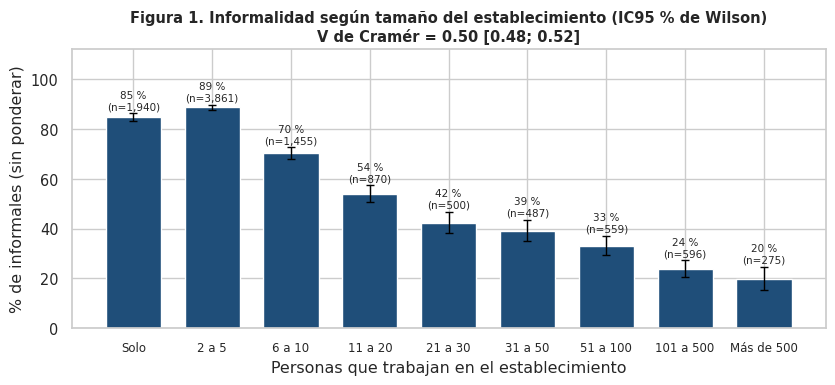

In [59]:
def guardar(nombre):
    plt.savefig(DIR_OUT / "figuras" / nombre, dpi=160, bbox_inches="tight")

# ---------- Figura 1. H1: informalidad por tamaño del establecimiento con IC de Wilson ----------
lo_w, hi_w = proportion_confint(ct.Informal, ct.n, method="wilson")
fig, ax = plt.subplots(figsize=(8.5, 4))
x_ = np.arange(len(ct))
ax.bar(x_, ct["% informal"], color=AZUL, width=0.7)
ax.errorbar(x_, ct["% informal"], yerr=[ct["% informal"] - 100 * lo_w, 100 * hi_w - ct["% informal"]], fmt="none", ecolor="black", capsize=3, lw=1)
for i_, (v_, n_) in enumerate(zip(ct["% informal"], ct.n)):
    ax.text(i_, 100 * hi_w.iloc[i_] + 1.5, f"{v_:.0f} %\n(n={n_:,})", ha="center", fontsize=7.5)
ax.set_xticks(x_); ax.set_xticklabels(ct.index, fontsize=8.5)
ax.set_ylim(0, 112); ax.set_xlabel("Personas que trabajan en el establecimiento"); ax.set_ylabel("% de informales (sin ponderar)")
ax.set_title(f"Figura 1. Informalidad según tamaño del establecimiento (IC95 % de Wilson)\nV de Cramér = {V_H1:.2f} [{ic_v[0]:.2f}; {ic_v[1]:.2f}]", fontsize=10.5, weight="bold")
plt.tight_layout(); guardar("fig1_h1_tamano.png"); plt.show()

**Interpretación.** La informalidad cae casi sin interrupción desde los establecimientos de 2 a 5 personas (89 %) hasta los de más de 500 (20 %); los IC95 % no se solapan entre tramos distantes. La excepción es el primer escalón (Solo < 2 a 5).

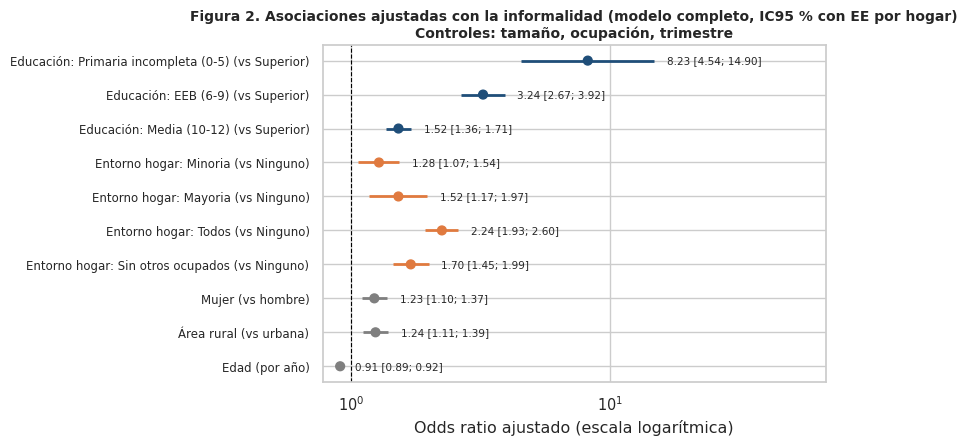

In [60]:
# ---------- Figura 2. Odds ratios ajustados del modelo completo (M3) ----------
etiquetas = {}
for n in m_ext.params.index:
    if n.startswith("C(educ_nivel"):
        etiquetas[n] = "Educación: " + n.split("[T.")[1].rstrip("]") + " (vs Superior)"
    elif "entorno_informal" in n:
        etiquetas[n] = "Entorno hogar: " + n.split("[T.")[1].rstrip("]") + " (vs Ninguno)"
etiquetas.update({"educ_anios": "Educación (por año)", "mujer": "Mujer (vs hombre)", "rural": "Área rural (vs urbana)", "edad": "Edad (por año)"})
orden_forest = [n for n in etiquetas if n in m_ext.params.index]
ors = np.exp(m_ext.params[orden_forest]); lo_f = np.exp(m_ext.params[orden_forest] - 1.96 * m_ext.bse[orden_forest]); hi_f = np.exp(m_ext.params[orden_forest] + 1.96 * m_ext.bse[orden_forest])
fig, ax = plt.subplots(figsize=(8.5, 4.6))
yy = np.arange(len(orden_forest))[::-1]
col = [NARANJA if "entorno" in n else (AZUL if "educ" in n else GRIS) for n in orden_forest]
ax.hlines(yy, lo_f, hi_f, color=col, lw=2)
ax.scatter(ors, yy, color=col, zorder=3, s=40)
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels([etiquetas[n] for n in orden_forest], fontsize=8.5)
ax.set_xlabel("Odds ratio ajustado (escala logarítmica)"); ax.set_ylabel("")
for yi, o_, lo_, hi_ in zip(yy, ors, lo_f, hi_f):
    ax.text(hi_ * 1.12, yi, f"{o_:.2f} [{lo_:.2f}; {hi_:.2f}]", va="center", fontsize=7.5)
ax.set_xlim(right=ax.get_xlim()[1] * 4)
ax.set_title("Figura 2. Asociaciones ajustadas con la informalidad (modelo completo, IC95 % con EE por hogar)\nControles: tamaño, ocupación, trimestre", fontsize=10, weight="bold")
plt.tight_layout(); guardar("fig2_forest_or.png"); plt.show()

**Interpretación.** Con las demás variables constantes, la educación y el entorno informal del hogar conservan una asociación clara (los IC no cruzan 1). Mujer y área rural muestran asociaciones pequeñas (OR ≈ 1,2) y la edad, un descenso de ≈ 9 % de las odds por año. La escala es logarítmica: las distancias a 1 son comparables entre OR mayores y menores que 1.

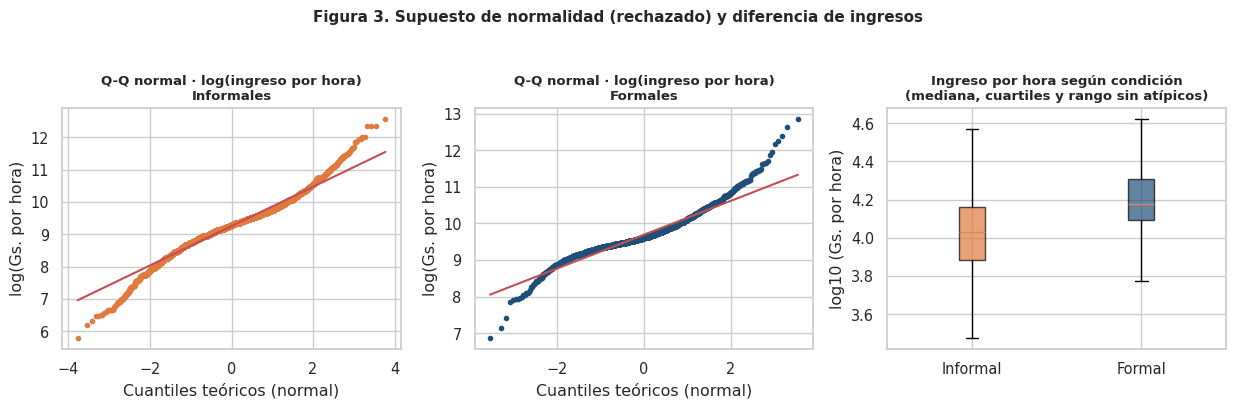

In [61]:
# ---------- Figura 3. H4: verificación de normalidad y comparación de ingresos ----------
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9))
for ax, (etq, g_, c_) in zip(axs[:2], [("Informales", inf, NARANJA), ("Formales", frm, AZUL)]):
    stats.probplot(np.log(g_.ingreso_hora.dropna()), dist="norm", plot=ax)
    ax.get_lines()[0].set_markerfacecolor(c_); ax.get_lines()[0].set_markeredgecolor(c_); ax.get_lines()[0].set_markersize(3)
    ax.set_title(f"Q-Q normal · log(ingreso por hora)\n{etq}", fontsize=9.5, weight="bold")
    ax.set_xlabel("Cuantiles teóricos (normal)"); ax.set_ylabel("log(Gs. por hora)")
bp = axs[2].boxplot([np.log10(inf.ingreso_hora.dropna()), np.log10(frm.ingreso_hora.dropna())], labels=["Informal", "Formal"], patch_artist=True, showfliers=False)
for p_, c_ in zip(bp["boxes"], [NARANJA, AZUL]): p_.set_facecolor(c_); p_.set_alpha(0.7)
axs[2].set_ylabel("log10 (Gs. por hora)"); axs[2].set_title("Ingreso por hora según condición\n(mediana, cuartiles y rango sin atípicos)", fontsize=9.5, weight="bold")
plt.suptitle("Figura 3. Supuesto de normalidad (rechazado) y diferencia de ingresos", fontsize=11, weight="bold", y=1.04)
plt.tight_layout(); guardar("fig3_h4_ingresos.png"); plt.show()

**Interpretación.** Las colas de los Q-Q se separan de la recta: la normalidad no se sostiene ni en logaritmos, lo que justifica la prueba no paramétrica. La caja de los formales está desplazada hacia valores mayores de ingreso por hora.

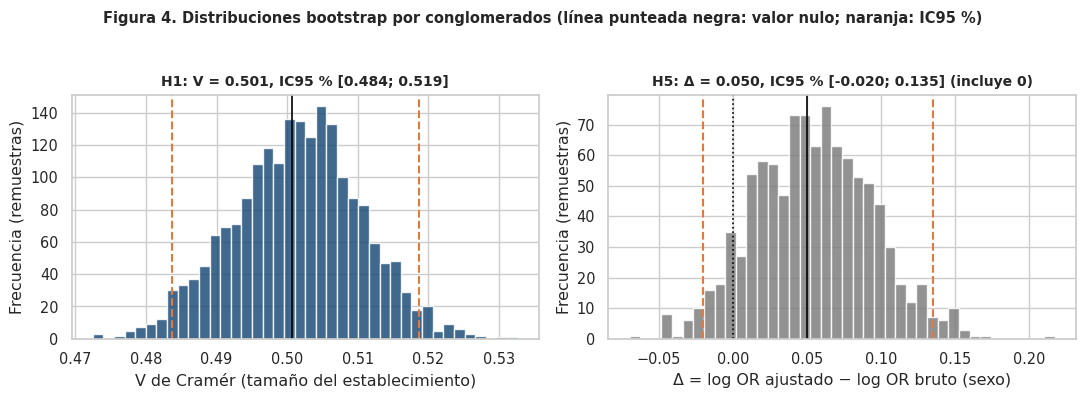

In [62]:
# ---------- Figura 4. Distribuciones bootstrap (remuestreo por hogar) ----------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(v_boot, bins=40, color=AZUL, alpha=0.85)
axs[0].axvline(V_H1, color="black", lw=1.2); [axs[0].axvline(q, color=NARANJA, ls="--") for q in ic_v]
axs[0].set_xlabel("V de Cramér (tamaño del establecimiento)"); axs[0].set_ylabel("Frecuencia (remuestras)")
axs[0].set_title(f"H1: V = {V_H1:.3f}, IC95 % [{ic_v[0]:.3f}; {ic_v[1]:.3f}]", fontsize=10, weight="bold")
axs[1].hist(delta_b, bins=40, color=GRIS, alpha=0.85)
axs[1].axvline(0, color="black", lw=1.2, ls=":"); axs[1].axvline(delta_obs, color="black", lw=1.2); [axs[1].axvline(q, color=NARANJA, ls="--") for q in ic_delta]
axs[1].set_xlabel("Δ = log OR ajustado − log OR bruto (sexo)"); axs[1].set_ylabel("Frecuencia (remuestras)")
axs[1].set_title(f"H5: Δ = {delta_obs:.3f}, IC95 % [{ic_delta[0]:.3f}; {ic_delta[1]:.3f}] (incluye 0)", fontsize=10, weight="bold")
plt.suptitle("Figura 4. Distribuciones bootstrap por conglomerados (línea punteada negra: valor nulo; naranja: IC95 %)", fontsize=10.5, weight="bold", y=1.04)
plt.tight_layout(); guardar("fig4_bootstrap.png"); plt.show()

**Interpretación.** El IC de V (H1) está lejos de 0 y de los umbrales de efecto pequeño. El de Δ (H5) contiene el 0: no hay evidencia suficiente de que el OR de sexo cambie al ajustar.

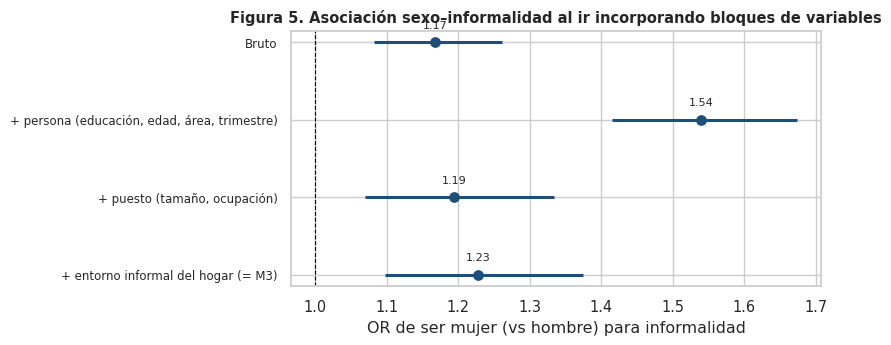

In [63]:
# ---------- Figura 5. H5: el OR de sexo según los bloques de variables incorporados ----------
fig, ax = plt.subplots(figsize=(8.5, 3.6))
yy = np.arange(len(seq))[::-1]
lo_s = seq["IC95 %"].str.strip("[]").str.split(";").str[0].astype(float); hi_s = seq["IC95 %"].str.strip("[]").str.split(";").str[1].astype(float)
ax.hlines(yy, lo_s, hi_s, color=AZUL, lw=2.2); ax.scatter(seq["OR mujer vs hombre"], yy, color=AZUL, s=45, zorder=3)
ax.axvline(1, color="black", ls="--", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(seq.Modelo, fontsize=8.5); ax.set_xlabel("OR de ser mujer (vs hombre) para informalidad")
for yi, o_ in zip(yy, seq["OR mujer vs hombre"]): ax.text(o_, yi + 0.18, f"{o_:.2f}", ha="center", fontsize=8)
ax.set_title("Figura 5. Asociación sexo–informalidad al ir incorporando bloques de variables", fontsize=10.5, weight="bold")
plt.tight_layout(); guardar("fig5_h5_sexo_secuencial.png"); plt.show()

**Interpretación.** El OR de sexo sube al controlar por la mayor educación de las mujeres y vuelve a bajar al controlar por tamaño y ocupación: dos efectos de signo opuesto que explican por qué el OR final se parece al bruto.

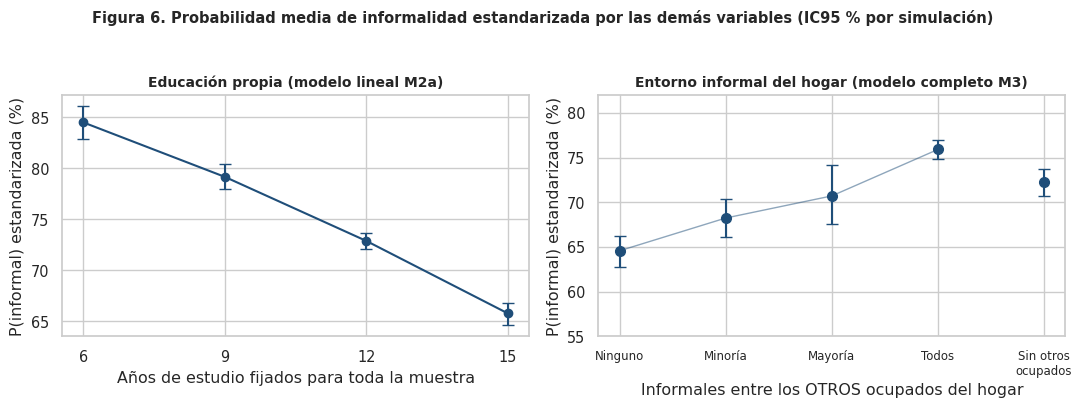

In [64]:
# ---------- Figura 6. Probabilidades estandarizadas (efecto en puntos porcentuales) ----------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
anios = [6, 9, 12, 15]
pe = [prob_media_sim(m_lin, {"educ_anios": a}) for a in anios]
axs[0].errorbar(anios, [100 * p[0] for p in pe], yerr=[[100 * (p[0] - p[1]) for p in pe], [100 * (p[2] - p[0]) for p in pe]], fmt="-o", color=AZUL, capsize=4)
axs[0].set_xticks(anios); axs[0].set_xlabel("Años de estudio fijados para toda la muestra"); axs[0].set_ylabel("P(informal) estandarizada (%)")
axs[0].set_title("Educación propia (modelo lineal M2a)", fontsize=10, weight="bold")
cats = ["Ninguno", "Minoria", "Mayoria", "Todos", "Sin otros ocupados"]
pe2 = [prob_media_sim(m_ext, {"entorno_informal": c}) for c in cats]
axs[1].errorbar(range(5), [100 * p[0] for p in pe2], yerr=[[100 * (p[0] - p[1]) for p in pe2], [100 * (p[2] - p[0]) for p in pe2]],
                fmt="o", color=AZUL, capsize=4, markersize=7)
axs[1].plot(range(4), [100 * p[0] for p in pe2[:4]], color=AZUL, lw=1, alpha=0.5)
axs[1].set_xticks(range(5)); axs[1].set_xticklabels(["Ninguno", "Minoría", "Mayoría", "Todos", "Sin otros\nocupados"], fontsize=8.5)
axs[1].set_ylim(55, 82); axs[1].set_xlabel("Informales entre los OTROS ocupados del hogar"); axs[1].set_ylabel("P(informal) estandarizada (%)")
axs[1].set_title("Entorno informal del hogar (modelo completo M3)", fontsize=10, weight="bold")
plt.suptitle("Figura 6. Probabilidad media de informalidad estandarizada por las demás variables (IC95 % por simulación)", fontsize=10.5, weight="bold", y=1.04)
plt.tight_layout(); guardar("fig6_prob_estandarizadas.png"); plt.show()

**Interpretación.** A igualdad de las demás variables, la probabilidad de informalidad baja ≈ 6–7 pp por cada tres años de estudio y sube 11 pp entre los entornos «Ninguno» y «Todos». Los puntos no se unen con barras para no truncar el eje en cero.

### Exportación a HTML

Este bloque de código exporta el cuaderno actual a formato HTML. Asegúrate de guardar los cambios en el cuaderno (`Ctrl + S` o `Cmd + S`) antes de ejecutarlo para que la exportación incluya todo el contenido más reciente.

In [67]:
import os
import json
from google.colab import _message

# 1. Definir el nombre del archivo del cuaderno solicitado por el usuario
cuaderno_objetivo = "Fase2_Inferencia_Informalidad_Juvenil.ipynb"
html_objetivo = cuaderno_objetivo.replace(".ipynb", ".html")

print(f"Preparando la exportación de: {cuaderno_objetivo}...")

try:
    # 2. Obtener de forma dinámica y segura el JSON del cuaderno desde la sesión del navegador en Colab
    print("Obteniendo el estado actual del cuaderno en memoria...")
    notebook_json = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]

    # 3. Guardar el archivo en el sistema de archivos local de la máquina virtual de Colab
    with open(cuaderno_objetivo, "w", encoding="utf-8") as f:
        json.dump(notebook_json, f, indent=2, ensure_ascii=False)
    print(f"Archivo local '{cuaderno_objetivo}' creado e inicializado con éxito.")

    # 4. Ejecutar el comando jupyter nbconvert de manera robusta usando la plantilla clásica
    print(f"Iniciando conversión a HTML clásico...")
    !jupyter nbconvert --to html --template classic "{cuaderno_objetivo}"

    # 5. Confirmar la existencia y ruta del archivo HTML de salida
    if os.path.exists(html_objetivo):
        print(f"\n¡Exportación completada de forma exitosa!")
        print(f"Archivo generado listo para descargar: {os.path.abspath(html_objetivo)}")
    else:
        print("\nOcurrió un problema inesperado: El archivo HTML no pudo ser localizado tras la exportación.")

except Exception as e:
    print(f"\nError durante la exportación dinámica: {e}")
    print("Procedimiento alternativo: Intenta descargar el cuaderno manualmente (.ipynb) desde 'Archivo' -> 'Descargar', súbelo al almacenamiento de Colab y vuelve a ejecutar nbconvert.")

Preparando la exportación de: Fase2_Inferencia_Informalidad_Juvenil.ipynb...
Obteniendo el estado actual del cuaderno en memoria...
Archivo local 'Fase2_Inferencia_Informalidad_Juvenil.ipynb' creado e inicializado con éxito.
Iniciando conversión a HTML clásico...
[NbConvertApp] Converting notebook Fase2_Inferencia_Informalidad_Juvenil.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 1207142 bytes to Fase2_Inferencia_Informalidad_Juvenil.html

¡Exportación completada de forma exitosa!
Archivo generado listo para descargar: /content/Fase2_Inferencia_Informalidad_Juvenil.html


In [68]:
from google.colab import files
import os

archivo_descargar = "Fase2_Inferencia_Informalidad_Juvenil.html"

if os.path.exists(archivo_descargar):
    print(f"Iniciando la descarga automática de: {archivo_descargar}")
    files.download(archivo_descargar)
else:
    print(f"Error: No se encontró el archivo '{archivo_descargar}' en el directorio actual. Asegúrate de ejecutar primero la celda de exportación.")

Iniciando la descarga automática de: Fase2_Inferencia_Informalidad_Juvenil.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusión de la Fase 2

### 9.1 Qué hipótesis se sostuvieron

| Hipótesis | Resultado | Magnitud |
|---|---|---|
| H1 · tamaño del establecimiento | **Se rechaza H0** | V = 0,50 (grande); informalidad de 89 % (2 a 5) a 20 % (> 500) |
| H2 · educación ajustada | **Se rechaza H0** | OR 9,4 / 3,7 / 1,6 frente a superior; ≈ −6 a −7 pp cada tres años de estudio |
| H3 · entorno informal del hogar | **Se rechaza H0** | OR «Todos» = 2,24; +11 pp; ΔAUC = 0,005 (aporte discriminante acotado) |
| H4 · ingresos menores en informales | **Se rechaza H0** | −33 % mensual, −28 % por hora (medianas); rango-biserial −0,62 / −0,47 |
| H5 · OR de sexo ajustado ≠ bruto | **No hay evidencia suficiente** | Δ = 0,05 [−0,02; 0,14]; OR ajustado 1,23 (pequeño) pero distinto de 1 |

### 9.2 Qué implica para la pregunta de investigación

Los resultados respaldan la hipótesis de que **la informalidad juvenil no se explica por un único factor**. El **puesto de trabajo** (tamaño del establecimiento y ocupación) es el correlato más fuerte; la **educación** conserva una asociación independiente, de magnitud moderada; el **entorno informal del hogar** agrega información propia, aunque con poco poder discriminante adicional; y el **sexo** tiene una asociación pequeña pero distinta de cero. Estos resultados describen asociaciones en una muestra transversal: ninguno permite afirmar causalidad ni evaluar el efecto de una política.

### 9.3 Limitaciones de la inferencia

- **Dependencia.** Hay hogares con varias personas y no existe identificador longitudinal; se mitigó con errores estándar y bootstrap por hogar, que dieron resultados casi idénticos a los ingenuos.
- **Diseño muestral.** No se dispone de estratos ni UPM originales: los IC no son completamente basados en el diseño y los contrastes principales no usan pesos (la sensibilidad ponderada coincide).
- **Posible circularidad.** Debe verificarse si la definición del INE de `INFORMALIDAD` incorpora el tamaño del establecimiento; de ser así, H1 sería en parte mecánica.
- **Calibración.** Hosmer-Lemeshow rechaza en todos los modelos; son explicativos, no predictivos.
- **Ingresos nominales y atípicos imputados** por el INE, con concentración en valores redondos.
- **Dependencia temporal.** Diez trimestres con rotación de panel; el trimestre se incluyó como control, pero no se modeló la correlación serial.

### 9.4 Variables que se llevan a la Fase 3

| Variable | Justificación según la evidencia |
|---|---|
| `tam_empresa` (con −1 y 11 como categorías) | Mayor asociación (V = 0,50). Entrenar **con y sin** esta variable por el riesgo de circularidad. |
| `ocupacion` (agrupada) | Asociación moderada (V = 0,34), controlada en todos los modelos |
| `educ_nivel` | Asociación independiente (H2); relación no lineal, por lo que se usa por niveles |
| `entorno_informal` (con «Sin otros ocupados») y `clima_educativo` | Aporte incremental (H3); el clima conserva efecto propio |
| `mujer`, `rural`, `edad`, `periodo` | Asociaciones pequeñas pero estables (OR ≈ 1,2; edad 0,91 por año) |
| `rama`, `horas`, `antiguedad`, `departamento` | Candidatas: no se contrastaron en esta fase |
| **Excluidas:** `ingreso`, `ingreso_hora` | Consecuencia de la informalidad (H4), no predictor; se usarían solo con fuga de información |

**Recomendaciones de diseño para la Fase 3:** partición **cronológica** (entrenar con 2024-2025, probar en 2026) y **por hogar**, para que miembros del mismo hogar no queden en entrenamiento y prueba; línea base de clase mayoritaria (71,2 % sin ponderar), por lo que la exactitud sola no es métrica válida; y evaluar el conjunto de prueba una sola vez.

---

## Anexo — Declaración de uso de asistentes de inteligencia artificial

Conforme al reglamento de la cátedra, se declara el uso de un asistente de inteligencia artificial (Claude, de Anthropic) como herramienta de apoyo en esta fase: redacción del código de los contrastes y de las funciones auxiliares, generación de las figuras, y redacción de las interpretaciones a partir de las salidas del cuaderno. Las decisiones metodológicas (pregunta, hipótesis, nivel de significancia, regla de decisión ante el incumplimiento de supuestos, variables que pasan a la Fase 3) y la interpretación de resultados deben ser revisadas, comprendidas y asumidas por el grupo, que está en condiciones de responder sobre cualquier parte del trabajo.